# ANÁLISE DE DADOS PARA OTIMIZAÇÃO DAS DESPESAS DE MARKETING PARA A EMPRESA Y.Afisha #

Análise com objetivo de encontrar otimizações nas desperas com o marketing da Y.Afisha, analisando o comportamento dos usuários os dias no qual elas começam a comprar e qual é a receita que cada usuário traz a empresa. E quando as despesas da empresa começam a ser coberta. Quanto dinheiro foi gasto por total em origem de tempo, quanto custou cada origem, e se os investimentos valeram a pena.
Analisaremos Kpis, CAC, receita da empresa e mais alguns fatores para chegarmos as respostas.




# Legenda dos Dados #
## A tabela visits (os logs do servidor com dados sobre os acessos ao site): ##

-Uid — identificador unívoco do usuário

-Device — dispositivo do usuário

-Start Ts — data e hora do início da sessão

-End Ts — data e hora do final da sessão

-Source Id — identificador da origem do anúncio através do qual o usuário chegou
Todas as datas nesta tabela estão no formato YYYY-MM-DD.

## A tabela orders (dados sobre os pedidos): ##

-Uid — identificador unívoco do usuário que faz um pedido

-Buy Ts — data e hora do pedido

-Revenue — a receita da Y.Afisha com o pedido

## A tabela costs (dados sobre as despesas com marketing): ##

-source_id — identificador da origem de anúncio

-dt — data

-costs — despesas com esta origem de anúncio neste dia

# VISÃO E ANÁLISE DOS DADOS #
Nesta etapa irei fazer a visão e analise de dados,verificando os valores nulos, duplicatas, tipos de dados e se caso ter necessidade alterar os tipo de dados. Ao longo do notebook também vou carregar e limpar orders e costs. Vou separar por Ánalise as tabelas.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [7]:

visits = pd.read_csv('/datasets/visits_log_us.csv')
print(visits.info())
print()
visits.head()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 359400 entries, 0 to 359399
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   Device     359400 non-null  object
 1   End Ts     359400 non-null  object
 2   Source Id  359400 non-null  int64 
 3   Start Ts   359400 non-null  object
 4   Uid        359400 non-null  uint64
dtypes: int64(1), object(3), uint64(1)
memory usage: 13.7+ MB
None



,Device,End Ts,Source Id,Start Ts,Uid
0,touch,2017-12-20 17:38:00,4,2017-12-20 17:20:00,16879256277535980062
1,desktop,2018-02-19 17:21:00,2,2018-02-19 16:53:00,104060357244891740
2,touch,2017-07-01 01:54:00,5,2017-07-01 01:54:00,7459035603376831527
3,desktop,2018-05-20 11:23:00,9,2018-05-20 10:59:00,16174680259334210214
4,desktop,2017-12-27 14:06:00,3,2017-12-27 14:06:00,9969694820036681168


In [8]:

#arrumando as ordens das colunas 
visits= visits[['Source Id', 'Uid', 'Start Ts', 'End Ts', 'Device']]


#verificação de numeros núlos e duplicados 
print(visits.duplicated().sum())
print(visits.isna().sum())



#alteração de dados objects para datetime 
visits[['Start Ts', 'End Ts']] = (visits[['Start Ts', 'End Ts']]
    .apply(pd.to_datetime)
                                 )
#vendo os valores unicos na coluna 
device_source_counts = (
    visits[['Device', 'Source Id']]
    .value_counts()
    .reset_index(name='count')
)
print(visits.info())
print()
print(device_source_counts)






0
Source Id    0
Uid          0
Start Ts     0
End Ts       0
Device       0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 359400 entries, 0 to 359399
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   Source Id  359400 non-null  int64         
 1   Uid        359400 non-null  uint64        
 2   Start Ts   359400 non-null  datetime64[ns]
 3   End Ts     359400 non-null  datetime64[ns]
 4   Device     359400 non-null  object        
dtypes: datetime64[ns](2), int64(1), object(1), uint64(1)
memory usage: 13.7+ MB
None

     Device  Source Id  count
0   desktop          4  67640
1   desktop          3  65777
2   desktop          5  50069
3   desktop          2  35661
4     touch          4  34154
5   desktop          1  25901
6     touch          3  19833
7     touch          5  16836
8     touch          2  11965
9   desktop          9  10119
10    touch          1   8220
11  desktop      

# RESULTADOS DA LIMPEZA 
Não existia numeros nulos e nem duplicados no meu data, as colunas que tinham dados de tempo, estavam em obj transformei em datetime todas as duas colunas para conseguirmos fazer a análise de dados com os dados corretos.
# IDENTIFICANDO QUANTAS PESSOAS USAM-NO CADA DIA, DA SEMANA E DO MÊS


In [9]:

# manter somente o período completo até maio de 2018
visits_complete = visits[
    visits['Start Ts'] < '2018-06-01'
].copy()

# criando colunas de dia, semana e mês
visits_complete['date'] = visits_complete['Start Ts'].dt.date
visits_complete['week'] = visits_complete['Start Ts'].dt.to_period('W')
visits_complete['month'] = visits_complete['Start Ts'].dt.to_period('M')

# função para calcular usuários únicos por período
def unique_users_by_period(data, period):
    return (
        data
        .groupby(period)['Uid']
        .nunique()
    )

# usuários únicos por dia, semana e mês
users_per_day = unique_users_by_period(
    visits_complete,
    'date'
)

users_per_week = unique_users_by_period(
    visits_complete,
    'week'
)

users_per_month = unique_users_by_period(
    visits_complete,
    'month'
)

# retirar primeira e última semana porque são períodos parciais
users_per_week_complete = users_per_week.iloc[1:-1]

# média de usuários por dia, semana e mês
DAU = round(users_per_day.mean(), 2)
WAU = round(users_per_week_complete.mean(), 2)
MAU = round(users_per_month.mean(), 2)

print('A média de usuários por dia:', DAU)
print('A média de usuários por semana:', WAU)
print('A média de usuários por mês:', MAU)


# função para calcular usuários únicos por período e device
def unique_users_by_period_device(data, period):
    return (
        data
        .groupby([period, 'Device'])['Uid']
        .nunique()
        .unstack()
    )

# usuários únicos por dia, semana e mês por device
users_per_day_device = unique_users_by_period_device(
    visits_complete,
    'date'
)

users_per_week_device = unique_users_by_period_device(
    visits_complete,
    'week'
)

users_per_month_device = unique_users_by_period_device(
    visits_complete,
    'month'
)

# retirar primeira e última semana parcial
users_per_week_device_complete = (
    users_per_week_device.iloc[1:-1]
)

# média de usuários únicos por device
DAU_DEVICE = (
    users_per_day_device
    .mean()
    .round(2)
)

WAU_DEVICE = (
    users_per_week_device_complete
    .mean()
    .round(2)
)

MAU_DEVICE = (
    users_per_month_device
    .mean()
    .round(2)
)

print()

print('Separação de DAU, WAU, MAU por Device')

print('\nDAU POR DEVICE:')
print(
    DAU_DEVICE
    .rename_axis(None)
    .to_string(header=False)
)

print('\nWAU POR DEVICE:')
print(
    WAU_DEVICE
    .rename_axis(None)
    .to_string(header=False)
)

print('\nMAU POR DEVICE:')
print(
    MAU_DEVICE
    .rename_axis(None)
    .to_string(header=False)
)



A média de usuários por dia: 907.99
A média de usuários por semana: 5804.86
A média de usuários por mês: 23228.42

Separação de DAU, WAU, MAU por Device

DAU POR DEVICE:
desktop    659.24
touch      252.87

WAU POR DEVICE:
desktop    4196.00
touch      1657.71

MAU POR DEVICE:
desktop    16724.92
touch       6825.92


# Numero de sessões que ocorrem por dia #
Na análise vou fazer dois agrupamentos, vou fazer o primeiro agrupamento com usuáriios realizando várias sessões e vou fazer também com sessões de usuários univocos contanto uma sessão por usuário, para ver quantos usuários univocos existem na plataforma e a diferença para as vezes que eles entram na plataforma.

Média de sessões por dia: 987.36
Mediana de sessões por dia: 1003.0


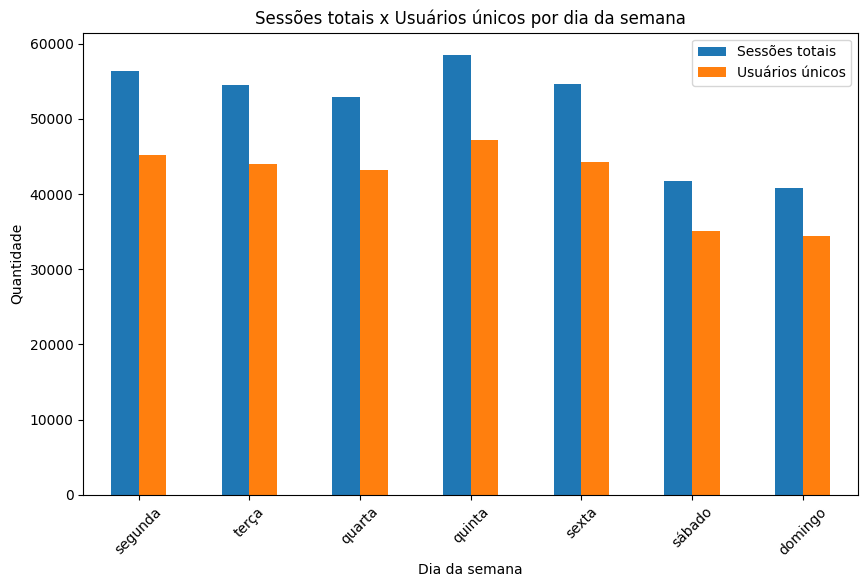


             total_sessions  unique_users
day_of_week                              
segunda               56301         45207
terça                 54518         44019
quarta                52956         43154
quinta                58523         47190
sexta                 54584         44200
sábado                41755         35110
domingo               40763         34418


In [15]:
# sessões totais por dia
sessions_per_day = (
    visits_complete
    .groupby('date')
    .size()
)

print(
    'Média de sessões por dia:',
    round(sessions_per_day.mean(), 2)
)

print(
    'Mediana de sessões por dia:',
    round(sessions_per_day.median(), 2)
)

# nomes dos dias da semana
days = {
    0: 'segunda',
    1: 'terça',
    2: 'quarta',
    3: 'quinta',
    4: 'sexta',
    5: 'sábado',
    6: 'domingo'
}

# criar dia da semana
visits_complete['day_of_week'] = (
    visits_complete['Start Ts']
    .dt.dayofweek
    .map(days)
)

# sessões totais por dia da semana
sessions_per_weekday = (
    visits_complete
    .groupby('day_of_week')
    .agg(
        total_sessions=('Uid', 'count')
    )
)

# usuários únicos por dia
sessions_per_day_unique = (
    visits_complete
    .groupby('date')
    .agg(
        unique_users=('Uid', 'nunique')
    )
)

# usuários únicos por dia da semana
sessions_per_weekday_nunique = (
    visits_complete
    .groupby('day_of_week')
    .agg(
        unique_users=('Uid', 'nunique')
    )
)

# ordem dos dias
days_order = [
    'segunda',
    'terça',
    'quarta',
    'quinta',
    'sexta',
    'sábado',
    'domingo'
]

# juntar sessões totais e usuários únicos
comparison = pd.concat(
    [
        sessions_per_weekday,
        sessions_per_weekday_nunique
    ],
    axis=1
)

comparison = comparison.reindex(days_order)

# gráfico
comparison.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title(
    'Sessões totais x Usuários únicos por dia da semana'
)

plt.xlabel('Dia da semana')
plt.ylabel('Quantidade')
plt.xticks(rotation=45)
plt.legend([
    'Sessões totais',
    'Usuários únicos'
])

plt.show()

print()
print(comparison)



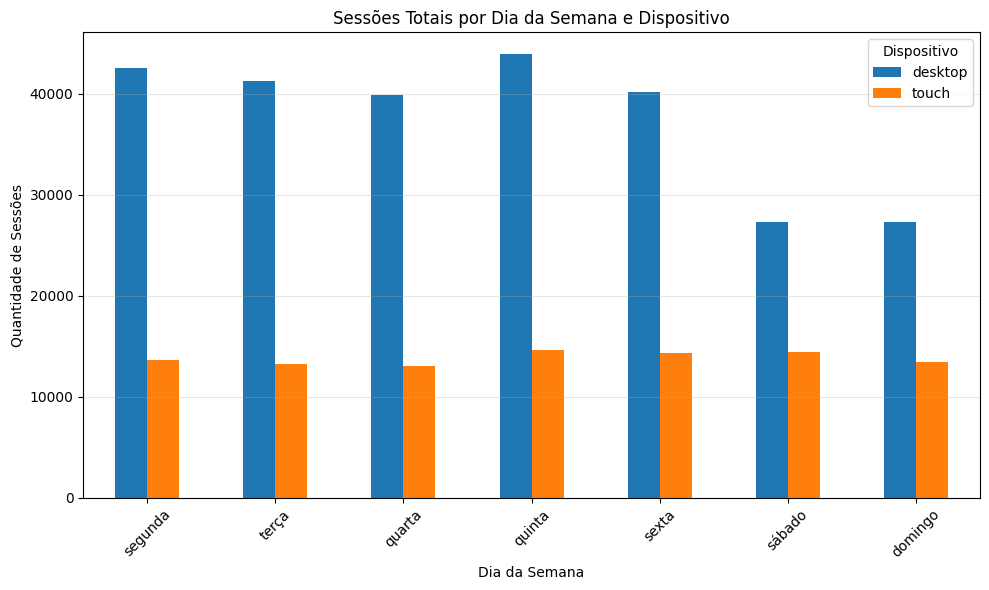

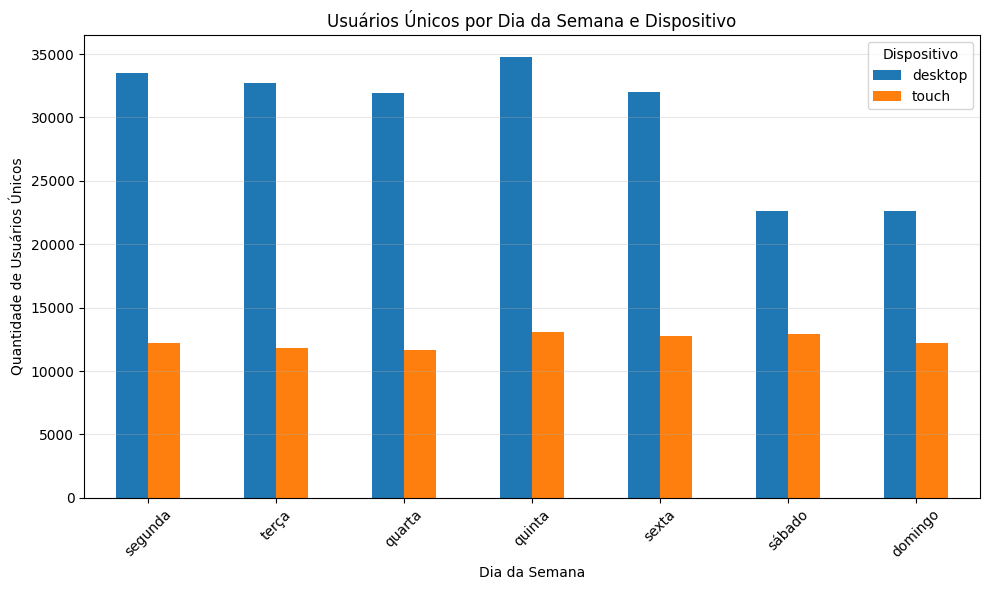

In [22]:
# sessões totais e usuários únicos por dia da semana e dispositivo
comparison_per_device = (
    visits_complete
    .groupby(['day_of_week', 'Device'])
    .agg(
        total_sessions=('Uid', 'count'),
        unique_users=('Uid', 'nunique')
    )
)

# colocar os dias na ordem correta
comparison_per_device = (
    comparison_per_device
    .reindex(
        days_order,
        level='day_of_week'
    )
)

# separar sessões totais
total_sessions_plot = (
    comparison_per_device[
        'total_sessions'
    ]
    .unstack('Device')
    .reindex(days_order)
)

# separar usuários únicos
unique_users_plot = (
    comparison_per_device[
        'unique_users'
    ]
    .unstack('Device')
    .reindex(days_order)
)

# gráfico 1 - sessões totais
total_sessions_plot.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title(
    'Sessões Totais por Dia da Semana e Dispositivo'
)

plt.xlabel('Dia da Semana')
plt.ylabel('Quantidade de Sessões')
plt.xticks(rotation=45)
plt.legend(title='Dispositivo')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


# gráfico 2 - usuários únicos
unique_users_plot.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title(
    'Usuários Únicos por Dia da Semana e Dispositivo'
)

plt.xlabel('Dia da Semana')
plt.ylabel('Quantidade de Usuários Únicos')
plt.xticks(rotation=45)
plt.legend(title='Dispositivo')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()



In [23]:
#mostrando a % com mais de uma sessão por dia
# número de sessões por usuário em cada dia
sessions_user_day = (
    visits_complete
    .groupby(['date', 'Uid'])
    .size()
    .reset_index(name='sessions')
)

# identificar usuários com mais de uma sessão no mesmo dia
sessions_user_day['repeated'] = (
    sessions_user_day['sessions'] > 1
)

# associar cada data ao dia da semana
date_weekday = (
    visits_complete[
        ['date', 'day_of_week']
    ]
    .drop_duplicates()
)

sessions_user_day = sessions_user_day.merge(
    date_weekday,
    on='date',
    how='left'
)

# percentual de usuários que repetiram sessão no mesmo dia
repeat_percentage = (
    sessions_user_day
    .groupby('day_of_week')['repeated']
    .mean()
    .mul(100)
    .reindex(days_order)
    .round(2)
)

print(
    'PERCENTUAL DE USUÁRIOS COM MAIS DE UMA SESSÃO NO MESMO DIA:'
)

print(repeat_percentage)

PERCENTUAL DE USUÁRIOS COM MAIS DE UMA SESSÃO NO MESMO DIA:
day_of_week
segunda    6.86
terça      7.06
quarta     6.96
quinta     7.09
sexta      7.35
sábado     6.28
domingo    5.84
Name: repeated, dtype: float64


# RESULTADOS DO PRIMEIRO COHORTE DE NUMERO DE SESSÕES UNICAS X TOTAIS 
Os maiores volumes de sessões na plataforma ocorrem entre segunda e sexta-feira, com destaque para a quinta-feira. A proporção de usuários que realizam mais de uma sessão no mesmo dia fica em torno de 6% a 7% nos dias úteis e próxima de 6% nos finais de semana. O volume de sessões e de usuários ativos é menor aos finais de semana, mas os dados disponíveis não permitem identificar a causa dessa redução. Também é possível observar que o volume de sessões em desktop é consideravelmente maior do que em touch, chegando, em alguns casos, a aproximadamente três vezes o volume observado em dispositivos móveis.

ESTATÍSTICAS DA DURAÇÃO EM SEGUNDOS:
count    359400.000000
mean        643.025687
std         997.127761
min       -2760.000000
25%         120.000000
50%         300.000000
75%         840.000000
max       42660.000000
Name: session_duration_sec, dtype: float64

Quantidade de sessões negativas: 2

Exemplos de sessões negativas:
                         Uid            Start Ts              End Ts  \
4181    13092152539246794986 2018-03-25 03:50:00 2018-03-25 03:18:00   
177972   4621202742905035453 2018-03-25 03:55:00 2018-03-25 03:09:00   

        session_duration_sec  
4181                 -1920.0  
177972               -2760.0  

ESTATÍSTICAS APÓS A LIMPEZA:
count    359398.00
mean         10.72
std          16.62
min           0.00
25%           2.00
50%           5.00
75%          14.00
max         711.00
Name: session_duration_min, dtype: float64

Sessões negativas após a limpeza: 0

Percentil 99 da duração: 75.0 minutos


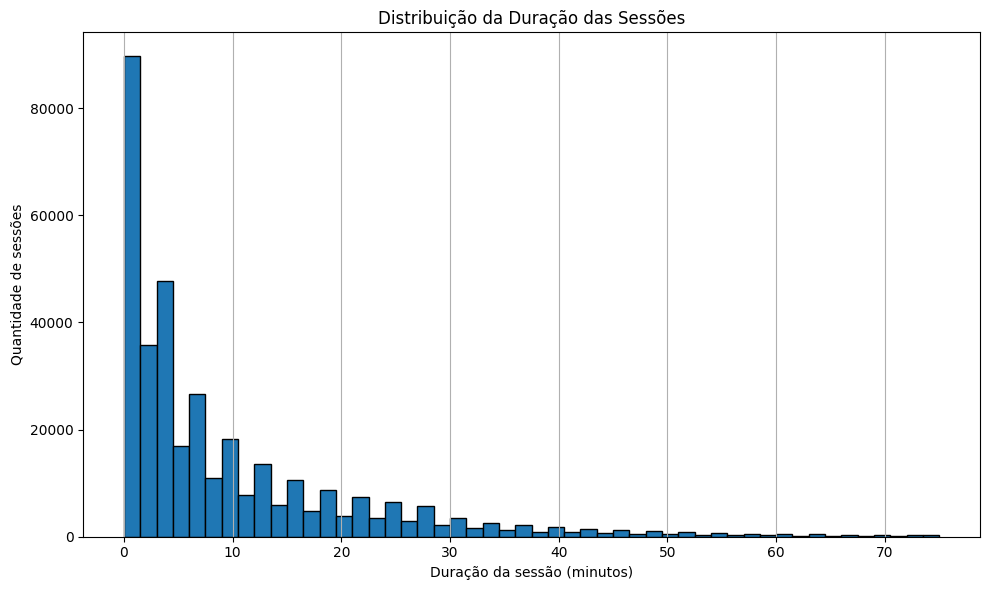

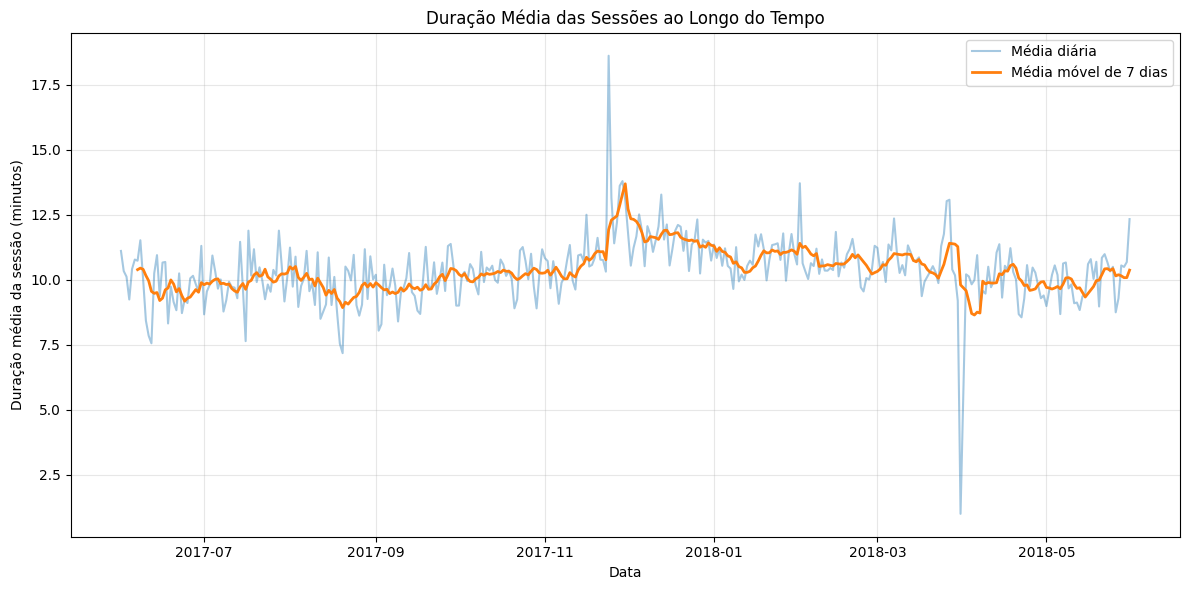


DURAÇÃO DAS SESSÕES POR DIA DA SEMANA:
             media_min  mediana_min  numero_sessoes
day_of_week                                        
segunda          10.77          5.0           56301
terça            10.93          5.0           54518
quarta           10.84          5.0           52956
quinta           10.80          5.0           58523
sexta            11.22          5.0           54584
sábado           10.15          5.0           41755
domingo           9.98          5.0           40761


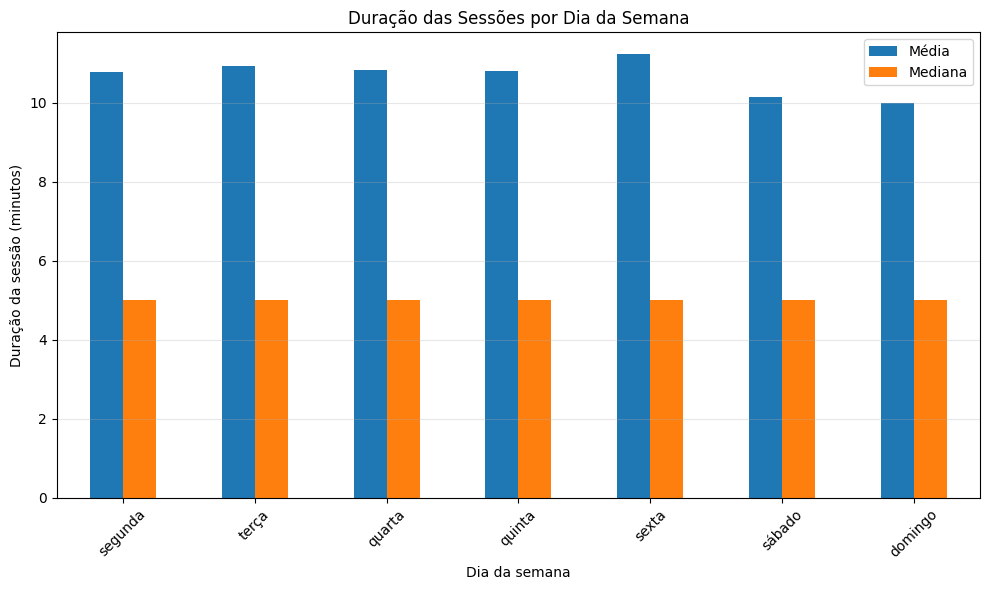


DURAÇÃO DAS SESSÕES POR DEVICE:
         media_min  mediana_min  numero_sessoes
Device                                         
desktop      11.72          6.0          262565
touch         7.99          3.0           96833


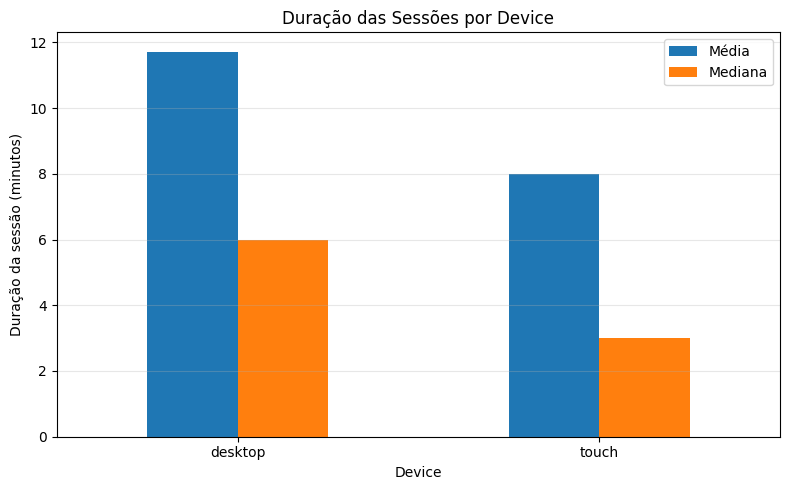


DURAÇÃO DAS SESSÕES POR ORIGEM:
           media_min  mediana_min  numero_sessoes
Source Id                                        
1              17.32         10.0           34121
2              14.08          7.0           47626
3               9.54          4.0           85609
4               9.33          4.0          101794
5               8.78          4.0           66905
6              22.83          7.0               6
7              10.11          3.0              36
9               9.44          4.0           13276
10             11.04          5.0           10025


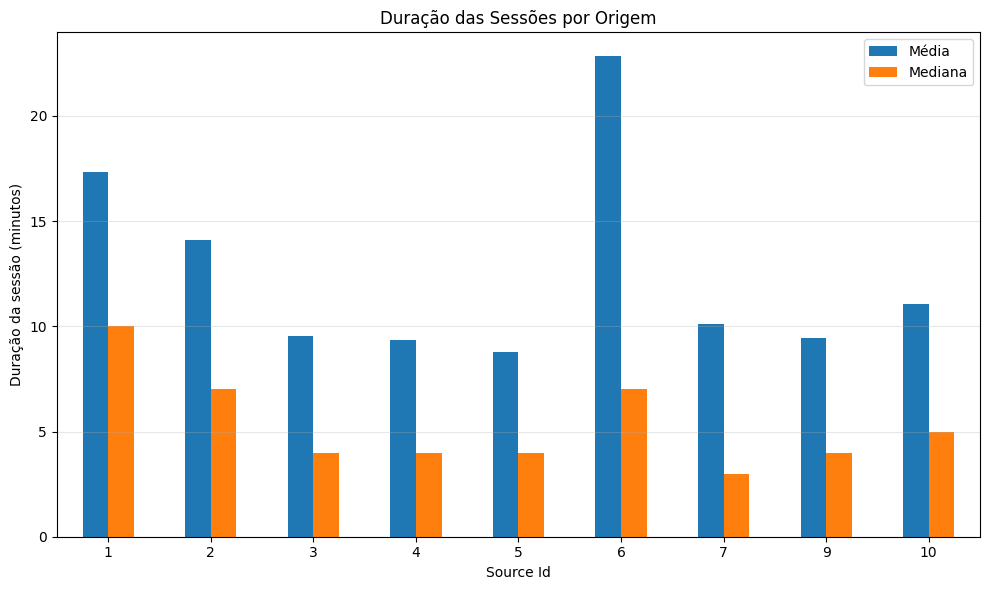

In [27]:
# duração das sessões

# garantir formato datetime
visits['Start Ts'] = pd.to_datetime(
    visits['Start Ts']
)

visits['End Ts'] = pd.to_datetime(
    visits['End Ts']
)

# calcular duração da sessão em segundos
visits['session_duration_sec'] = (
    visits['End Ts']
    - visits['Start Ts']
).dt.total_seconds()

# estatísticas antes da limpeza
print('ESTATÍSTICAS DA DURAÇÃO EM SEGUNDOS:')
print(
    visits['session_duration_sec'].describe()
)

# identificar sessões negativas
negative_sessions = visits[
    visits['session_duration_sec'] < 0
]

print(
    '\nQuantidade de sessões negativas:',
    negative_sessions.shape[0]
)

print('\nExemplos de sessões negativas:')
print(
    negative_sessions[
        [
            'Uid',
            'Start Ts',
            'End Ts',
            'session_duration_sec'
        ]
    ].head(20)
)

# substituir valores negativos por NaN
visits.loc[
    visits['session_duration_sec'] < 0,
    'session_duration_sec'
] = np.nan

# transformar segundos em minutos
visits['session_duration_min'] = (
    visits['session_duration_sec']
    / 60
)

# verificar depois da limpeza
print('\nESTATÍSTICAS APÓS A LIMPEZA:')
print(
    visits['session_duration_min']
    .describe()
    .round(2)
)

print(
    '\nSessões negativas após a limpeza:',
    (visits['session_duration_sec'] < 0).sum()
)


# excluir junho de 2018 incompleto
visits_complete = visits[
    visits['Start Ts'] < '2018-06-01'
].copy()

# criar coluna de data
visits_complete['date'] = (
    visits_complete['Start Ts']
    .dt.date
)

# dias da semana
days = {
    0: 'segunda',
    1: 'terça',
    2: 'quarta',
    3: 'quinta',
    4: 'sexta',
    5: 'sábado',
    6: 'domingo'
}

days_order = [
    'segunda',
    'terça',
    'quarta',
    'quinta',
    'sexta',
    'sábado',
    'domingo'
]

visits_complete['day_of_week'] = (
    visits_complete['Start Ts']
    .dt.dayofweek
    .map(days)
)


# gráfico 1 - distribuição da duração das sessões
limite = (
    visits_complete[
        'session_duration_min'
    ]
    .quantile(0.99)
)

print(
    '\nPercentil 99 da duração:',
    round(limite, 2),
    'minutos'
)

visits_complete.loc[
    visits_complete['session_duration_min'] <= limite,
    'session_duration_min'
].hist(
    bins=50,
    figsize=(10, 6),
    edgecolor='black'
)

plt.title(
    'Distribuição da Duração das Sessões'
)

plt.xlabel(
    'Duração da sessão (minutos)'
)

plt.ylabel(
    'Quantidade de sessões'
)

plt.grid(
    axis='y',
    alpha=0.3
)

plt.tight_layout()
plt.show()


# duração média das sessões por dia
time_sessions_per_day = (
    visits_complete
    .groupby(
        'date',
        as_index=False
    )
    .agg(
        avg_session_duration=(
            'session_duration_min',
            'mean'
        )
    )
)

# transformar data para datetime
time_sessions_per_day['date'] = (
    pd.to_datetime(
        time_sessions_per_day['date']
    )
)

# média móvel de 7 dias
time_sessions_per_day['rolling_7d'] = (
    time_sessions_per_day[
        'avg_session_duration'
    ]
    .rolling(7)
    .mean()
)


# gráfico 2 - duração ao longo do tempo
plt.figure(
    figsize=(12, 6)
)

plt.plot(
    time_sessions_per_day['date'],
    time_sessions_per_day[
        'avg_session_duration'
    ],
    alpha=0.4,
    label='Média diária'
)

plt.plot(
    time_sessions_per_day['date'],
    time_sessions_per_day[
        'rolling_7d'
    ],
    linewidth=2,
    label='Média móvel de 7 dias'
)

plt.title(
    'Duração Média das Sessões ao Longo do Tempo'
)

plt.xlabel('Data')

plt.ylabel(
    'Duração média da sessão (minutos)'
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()
plt.show()


# duração por dia da semana
duration_weekday = (
    visits_complete
    .groupby(
        'day_of_week'
    )['session_duration_min']
    .agg(
        ['mean', 'median', 'count']
    )
    .reindex(days_order)
    .round(2)
)

duration_weekday.columns = [
    'media_min',
    'mediana_min',
    'numero_sessoes'
]

print(
    '\nDURAÇÃO DAS SESSÕES POR DIA DA SEMANA:'
)

print(
    duration_weekday
)


# gráfico 3 - duração por dia da semana
duration_weekday[
    [
        'media_min',
        'mediana_min'
    ]
].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title(
    'Duração das Sessões por Dia da Semana'
)

plt.xlabel(
    'Dia da semana'
)

plt.ylabel(
    'Duração da sessão (minutos)'
)

plt.xticks(
    rotation=45
)

plt.legend(
    [
        'Média',
        'Mediana'
    ]
)

plt.grid(
    axis='y',
    alpha=0.3
)

plt.tight_layout()
plt.show()


# duração por dispositivo
duration_device = (
    visits_complete
    .groupby(
        'Device'
    )['session_duration_min']
    .agg(
        ['mean', 'median', 'count']
    )
    .round(2)
)

duration_device.columns = [
    'media_min',
    'mediana_min',
    'numero_sessoes'
]

print(
    '\nDURAÇÃO DAS SESSÕES POR DEVICE:'
)

print(
    duration_device
)


# gráfico 4 - duração por dispositivo
duration_device[
    [
        'media_min',
        'mediana_min'
    ]
].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title(
    'Duração das Sessões por Device'
)

plt.xlabel(
    'Device'
)

plt.ylabel(
    'Duração da sessão (minutos)'
)

plt.xticks(
    rotation=0
)

plt.legend(
    [
        'Média',
        'Mediana'
    ]
)

plt.grid(
    axis='y',
    alpha=0.3
)

plt.tight_layout()
plt.show()


# duração por origem
duration_source = (
    visits_complete
    .groupby(
        'Source Id'
    )['session_duration_min']
    .agg(
        ['mean', 'median', 'count']
    )
    .round(2)
)

duration_source.columns = [
    'media_min',
    'mediana_min',
    'numero_sessoes'
]

print(
    '\nDURAÇÃO DAS SESSÕES POR ORIGEM:'
)

print(
    duration_source
)


# gráfico 5 - duração por origem
duration_source[
    [
        'media_min',
        'mediana_min'
    ]
].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title(
    'Duração das Sessões por Origem'
)

plt.xlabel(
    'Source Id'
)

plt.ylabel(
    'Duração da sessão (minutos)'
)

plt.xticks(
    rotation=0
)

plt.legend(
    [
        'Média',
        'Mediana'
    ]
)

plt.grid(
    axis='y',
    alpha=0.3
)

plt.tight_layout()
plt.show()

# Resultados das Medidas de Frequência #
A distribuição da duração das sessões apresenta forte assimetria à direita, com grandes sessões de curta duração e uma pequena quantidade de sessões muito longas. Isso chama atenção para possíveis outliers, com isso analisei a duração média por dia da semana e observei pouca variação entre os dias mesmo os usuários tendo menos sessões aos finais de semana eles continuam ficando o mesmo tempo na plataforma, com sexta-feira apresentando a maior média e o fim de semana as menores. Com à presença de valores extremos, eu também fiz a análise da mediana pois com os valores muito altos em alguns usuários ele sobe a média para cima e com a mediana notei que os usuários tem os mesmos comportamentamentos de duração de sessões em todos os dias da semana

# MEDINDO A RETENÇÃO DOS USUÁRIOS # 


In [28]:
#descobrindo qual mês aconteceu cada visita 
visits['activity_month'] = (
    visits['Start Ts']
    .dt.to_period('M')
    .dt.to_timestamp()
)

#o primeiro mês que o usuário entrou na plataforma
visits['first_activity_month'] = (
    visits.groupby('Uid')['activity_month']
    .transform('min')
)
# tabela de tempo de vida de cada usuário 

visits['lifetime'] = (
    (visits['activity_month'].dt.year -
     visits['first_activity_month'].dt.year) * 12
    +
    (visits['activity_month'].dt.month -
     visits['first_activity_month'].dt.month)
)
#
cohort_data = visits.groupby(
    ['first_activity_month', 'lifetime']
).agg({
    'Uid': 'nunique'
}).reset_index()
cohort_data

,first_activity_month,lifetime,Uid
0,2017-06-01,0,13259
1,2017-06-01,1,1043
2,2017-06-01,2,713
3,2017-06-01,3,814
4,2017-06-01,4,909
...,...,...,...
73,2018-03-01,1,861
74,2018-03-01,2,557
75,2018-04-01,0,15709
76,2018-04-01,1,760


In [29]:


#tabela de rastramento de mudanças de usuários 
cohort_pivot = cohort_data.pivot(
    index='first_activity_month',
    columns='lifetime',
    values='Uid'
)

cohort_pivot



lifetime,0,1,2,3,4,5,6,7,8,9,10,11
first_activity_month,,,,,,,,,,,,
2017-06-01,13259.0,1043.0,713.0,814.0,909.0,947.0,809.0,766.0,694.0,674.0,539.0,596.0
2017-07-01,13140.0,737.0,674.0,738.0,765.0,633.0,596.0,601.0,510.0,376.0,361.0,NaN
2017-08-01,10181.0,783.0,640.0,639.0,510.0,448.0,370.0,402.0,284.0,265.0,NaN,NaN
2017-09-01,16704.0,1428.0,1156.0,847.0,658.0,632.0,599.0,404.0,381.0,NaN,NaN,NaN
2017-10-01,25977.0,2042.0,1357.0,1012.0,890.0,837.0,555.0,529.0,NaN,NaN,NaN,NaN
2017-11-01,27248.0,2133.0,1202.0,1054.0,919.0,638.0,594.0,NaN,NaN,NaN,NaN,NaN
2017-12-01,25268.0,1410.0,960.0,786.0,512.0,481.0,NaN,NaN,NaN,NaN,NaN,NaN
2018-01-01,22624.0,1351.0,890.0,565.0,458.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-02-01,22197.0,1267.0,565.0,446.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


RETENÇÃO POR COORTE (%):
lifetime                 0     1     2     3     4     5     6     7     8   \
first_activity_month                                                          
2017-06-01            100.0  7.87  5.38  6.14  6.86  7.14  6.10  5.78  5.23   
2017-07-01            100.0  5.61  5.13  5.62  5.82  4.82  4.54  4.57  3.88   
2017-08-01            100.0  7.69  6.29  6.28  5.01  4.40  3.63  3.95  2.79   
2017-09-01            100.0  8.55  6.92  5.07  3.94  3.78  3.59  2.42  2.28   
2017-10-01            100.0  7.86  5.22  3.90  3.43  3.22  2.14  2.04   NaN   
2017-11-01            100.0  7.83  4.41  3.87  3.37  2.34  2.18   NaN   NaN   
2017-12-01            100.0  5.58  3.80  3.11  2.03  1.90   NaN   NaN   NaN   
2018-01-01            100.0  5.97  3.93  2.50  2.02   NaN   NaN   NaN   NaN   
2018-02-01            100.0  5.71  2.55  2.01   NaN   NaN   NaN   NaN   NaN   
2018-03-01            100.0  4.18  2.71   NaN   NaN   NaN   NaN   NaN   NaN   
2018-04-01            100.0

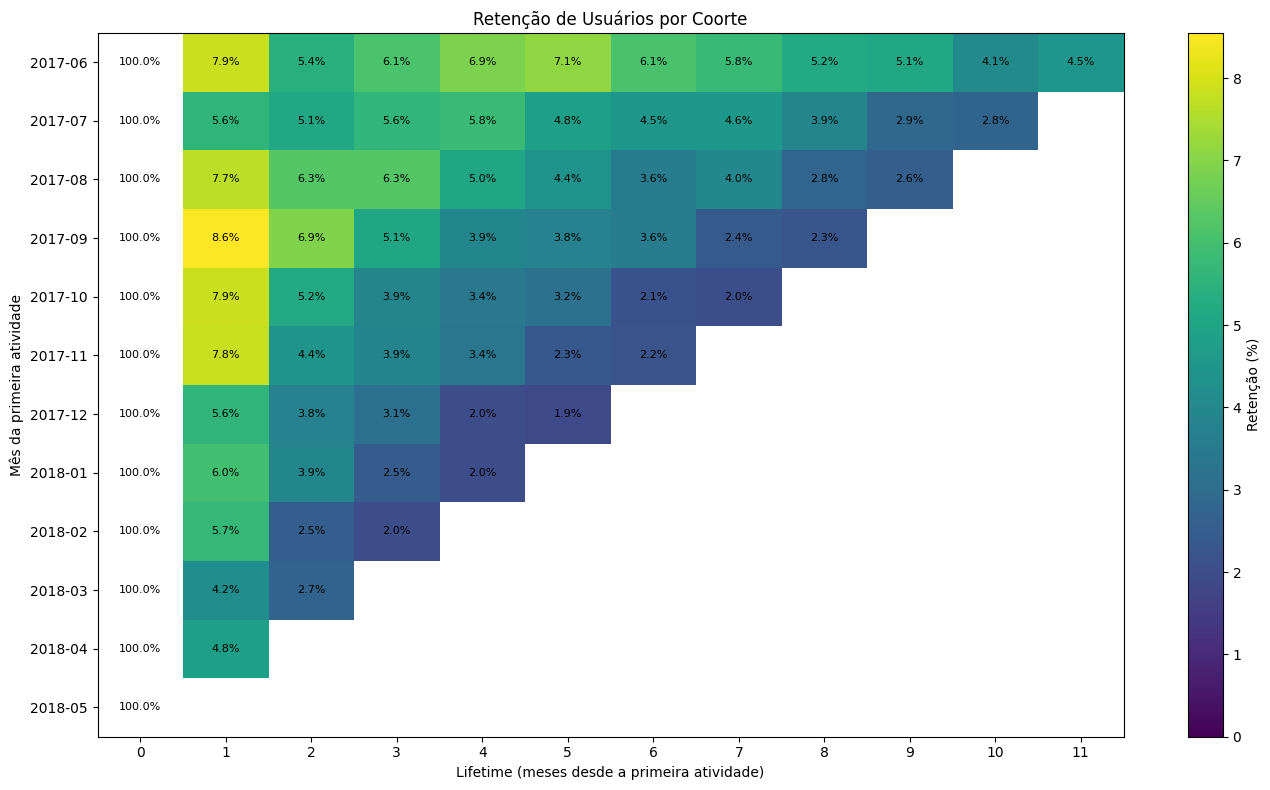

In [30]:

# tamanho inicial de cada coorte
cohort_sizes = cohort_pivot[0]

# calcular retenção
retention = cohort_pivot.divide(
    cohort_sizes,
    axis=0
)

# transformar em porcentagem
retention = (
    retention * 100
).round(2)

print('RETENÇÃO POR COORTE (%):')
print(retention)


# criar uma cópia apenas para o gráfico
retention_heatmap = retention.copy()

# retirar lifetime 0 da escala de cores
retention_heatmap.iloc[:, 0] = np.nan

# limite máximo baseado nos lifetimes após o mês inicial
max_retention = (
    retention.iloc[:, 1:]
    .max()
    .max()
)

plt.figure(figsize=(14, 8))

retention_masked = np.ma.masked_invalid(
    retention_heatmap.values
)

plt.imshow(
    retention_masked,
    aspect='auto',
    vmin=0,
    vmax=max_retention
)

plt.colorbar(
    label='Retenção (%)'
)

# lifetime no eixo X
plt.xticks(
    ticks=range(len(retention.columns)),
    labels=retention.columns
)

# coortes no eixo Y
plt.yticks(
    ticks=range(len(retention.index)),
    labels=[
        date.strftime('%Y-%m')
        for date in retention.index
    ]
)

# adicionar valores nas células
for i in range(len(retention.index)):
    for j in range(len(retention.columns)):

        value = retention.iloc[i, j]

        if pd.notna(value):
            plt.text(
                j,
                i,
                f'{value:.1f}%',
                ha='center',
                va='center',
                fontsize=8
            )

plt.title('Retenção de Usuários por Coorte')

plt.xlabel(
    'Lifetime (meses desde a primeira atividade)'
)

plt.ylabel(
    'Mês da primeira atividade'
)

plt.tight_layout()
plt.show()

In [32]:
#Medindo stickiness
monthly_stickiness = (DAU / MAU) * 100
print('DAU/MAU:', round(monthly_stickiness, 2), '%')


DAU/MAU: 3.91 %


# RESULTADOS DAS MEDIDAS DE RETENÇÃO #
A recorrência dos usuários é baixa após o primeiro mês. Em média, aproximadamente 6,5% das coortes retornam no mês seguinte à primeira atividade. Nos meses posteriores, a proporção de usuários ativos tende a permanecer em níveis ainda menores, em torno de 4% a 5%, chegando a aproximadamente 3,7% seis meses após a primeira atividade. Os indicadores  mostram que 3,91% média dos usuários ativos diariamente fazem parte da base média (MAU) ativa mensal, indicando que muitos usuários não acessam a plataforma diariamente.

# Ánalise de vendas #
Nessa etapa do projeto vamos analisar quando as pessoas começam a comprar, quantos pedidos os clientes fazem durante um determinado período de tempo, qual o volume médio de compra, e o LTV.

In [33]:
#carregando o arquivo
orders = pd.read_csv('/datasets/orders_log_us.csv')
print(orders.info())
print()
print(orders.describe())
print()
orders.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50415 entries, 0 to 50414
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Buy Ts   50415 non-null  object 
 1   Revenue  50415 non-null  float64
 2   Uid      50415 non-null  uint64 
dtypes: float64(1), object(1), uint64(1)
memory usage: 1.2+ MB
None

            Revenue           Uid
count  50415.000000  5.041500e+04
mean       4.999647  9.098161e+18
std       21.818359  5.285742e+18
min        0.000000  3.135781e+14
25%        1.220000  4.533567e+18
50%        2.500000  9.102274e+18
75%        4.890000  1.368290e+19
max     2633.280000  1.844617e+19



,Buy Ts,Revenue,Uid
0,2017-06-01 00:10:00,17.00,10329302124590727494
1,2017-06-01 00:25:00,0.55,11627257723692907447
2,2017-06-01 00:27:00,0.37,17903680561304213844
3,2017-06-01 00:29:00,0.55,16109239769442553005
4,2017-06-01 07:58:00,0.37,14200605875248379450


In [34]:
#arrumando as ordens das colunas 
orders= orders[['Uid', 'Buy Ts', 'Revenue']]

#verificação de numeros núlos e duplicados 
print(orders.duplicated().sum())
print(orders.isna().sum())

#alteração de dados objects para datetime 
orders['Buy Ts'] = (orders['Buy Ts']
    .apply(pd.to_datetime)
)
print(orders.info())



0
Uid        0
Buy Ts     0
Revenue    0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50415 entries, 0 to 50414
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   Uid      50415 non-null  uint64        
 1   Buy Ts   50415 non-null  datetime64[ns]
 2   Revenue  50415 non-null  float64       
dtypes: datetime64[ns](1), float64(1), uint64(1)
memory usage: 1.2 MB
None


In [35]:

# garantindo que as colunas estejam em datetime
visits['Start Ts'] = pd.to_datetime(
    visits['Start Ts'],
    errors='coerce'
)

orders['Buy Ts'] = pd.to_datetime(
    orders['Buy Ts'],
    errors='coerce'
)

# primeira visita de cada usuário
first_visits = (
    visits
    .groupby('Uid', as_index=False)
    .agg({'Start Ts': 'min'})
    .rename(columns={'Start Ts': 'first_visit'})
)

# primeira compra de cada usuário
first_orders = (
    orders
    .groupby('Uid', as_index=False)
    .agg({'Buy Ts': 'min'})
    .rename(columns={'Buy Ts': 'first_order'})
)

# garantindo datetime nas novas tabelas
first_visits['first_visit'] = pd.to_datetime(
    first_visits['first_visit'],
    errors='coerce'
)

first_orders['first_order'] = pd.to_datetime(
    first_orders['first_order'],
    errors='coerce'
)

# juntar primeira visita e primeira compra
conversion = first_visits.merge(
    first_orders,
    on='Uid',
    how='left'
)

# garantindo datetime depois do merge
conversion['first_visit'] = pd.to_datetime(
    conversion['first_visit'],
    errors='coerce'
)

conversion['first_order'] = pd.to_datetime(
    conversion['first_order'],
    errors='coerce'
)

# tempo exato até a primeira compra
conversion['time_to_conversion'] = (
    conversion['first_order']
    - conversion['first_visit']
)

# tempo exato em dias
conversion['conversion_days_exact'] = (
    conversion['time_to_conversion']
    .dt.total_seconds()
    .div(86400)
)

# dia de calendário da conversão
first_order_date = (
    conversion['first_order']
    .dt.floor('D')
)

first_visit_date = (
    conversion['first_visit']
    .dt.floor('D')
)

conversion['conversion_day'] = (
    first_order_date
    - first_visit_date
).dt.days

# verificando os dados
print(
    conversion[
        [
            'Uid',
            'first_visit',
            'first_order',
            'conversion_days_exact',
            'conversion_day'
        ]
    ].head(10)
)

# verificando conversões negativas
negative_conversions = (
    conversion['conversion_days_exact'] < 0
).sum()

print(
    'Conversões negativas:',
    negative_conversions
)

# frequência de conversão por dia
conversion_frequency = (
    conversion
    .dropna(subset=['conversion_day'])
    .groupby('conversion_day')['Uid']
    .nunique()
    .reset_index(name='users')
)

# total de usuários que compraram
total_converted_users = (
    conversion['first_order']
    .notna()
    .sum()
)

# porcentagem entre os usuários que converteram
conversion_frequency['conversion_pct'] = (
    conversion_frequency['users']
    / total_converted_users
    * 100
).round(2)

print(conversion_frequency.head(20))

# kpi 0 dias
conversion_0d = (
    conversion['conversion_day'] == 0
).mean() * 100

print(
    'Conversão 0 dias:',
    round(conversion_0d, 2),
    '%'
)

# kpi até 7 dias
conversion_7d = (
    conversion['conversion_day'] <= 7
).mean() * 100

print(
    'Conversão até 7 dias:',
    round(conversion_7d, 2),
    '%'
)

# kpi até 14 dias
conversion_14d = (
    conversion['conversion_day'] <= 14
).mean() * 100

print(
    'Conversão até 14 dias:',
    round(conversion_14d, 2),
    '%'
)

# kpi até 30 dias
conversion_30d = (
    conversion['conversion_day'] <= 30
).mean() * 100

print(
    'Conversão até 30 dias:',
    round(conversion_30d, 2),
    '%'
)

# tempo típico de conversão
converted = (
    conversion
    .dropna(subset=['conversion_days_exact'])
)

mean_conversion = (
    converted['conversion_days_exact']
    .mean()
)

median_conversion = (
    converted['conversion_days_exact']
    .median()
)

print()
print('Tempo típico de conversão')

print(
    'Mediana:',
    round(median_conversion, 2),
    'dias'
)

print(
    'Média:',
    round(mean_conversion, 2),
    'dias'
)

               Uid         first_visit         first_order  \
0   11863502262781 2018-03-01 17:27:00                 NaT   
1   49537067089222 2018-02-06 15:55:00                 NaT   
2  297729379853735 2017-06-07 18:47:00                 NaT   
3  313578113262317 2017-09-18 22:49:00 2018-01-03 21:51:00   
4  325320750514679 2017-09-30 14:29:00                 NaT   
5  397399764396656 2018-01-18 12:32:00                 NaT   
6  407573351275847 2017-06-17 13:40:00                 NaT   
7  498809019029702 2018-02-21 22:09:00                 NaT   
8  526778907996220 2017-10-21 17:51:00                 NaT   
9  577434573913691 2018-01-28 14:15:00                 NaT   

   conversion_days_exact  conversion_day  
0                    NaN             NaN  
1                    NaN             NaN  
2                    NaN             NaN  
3             106.959722           107.0  
4                    NaN             NaN  
5                    NaN             NaN  
6               

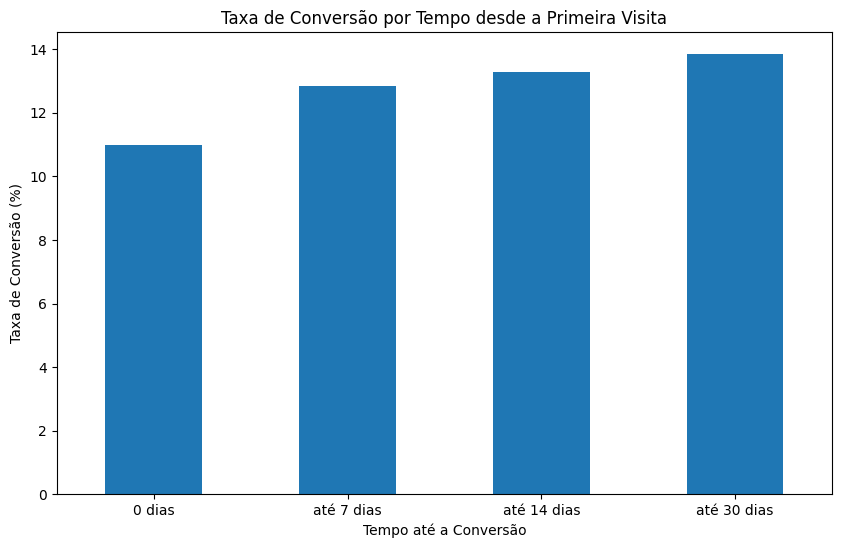

In [36]:
# organizar os KPIs em uma Series
conversion_kpis = pd.Series({
    '0 dias': conversion_0d,
    'até 7 dias': conversion_7d,
    'até 14 dias': conversion_14d,
    'até 30 dias': conversion_30d
})

# gráfico
conversion_kpis.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Taxa de Conversão por Tempo desde a Primeira Visita')
plt.xlabel('Tempo até a Conversão')
plt.ylabel('Taxa de Conversão (%)')
plt.xticks(rotation=0)

plt.show()




               Uid         first_visit         first_order  conversion_day  \
0   11863502262781 2018-03-01 17:27:00                 NaT             NaN   
1   49537067089222 2018-02-06 15:55:00                 NaT             NaN   
2  297729379853735 2017-06-07 18:47:00                 NaT             NaN   
3  313578113262317 2017-09-18 22:49:00 2018-01-03 21:51:00           107.0   
4  325320750514679 2017-09-30 14:29:00                 NaT             NaN   
5  397399764396656 2018-01-18 12:32:00                 NaT             NaN   
6  407573351275847 2017-06-17 13:40:00                 NaT             NaN   
7  498809019029702 2018-02-21 22:09:00                 NaT             NaN   
8  526778907996220 2017-10-21 17:51:00                 NaT             NaN   
9  577434573913691 2018-01-28 14:15:00                 NaT             NaN   

  first_device conversion_period  
0        touch     não converteu  
1        touch     não converteu  
2      desktop     não converteu  
3

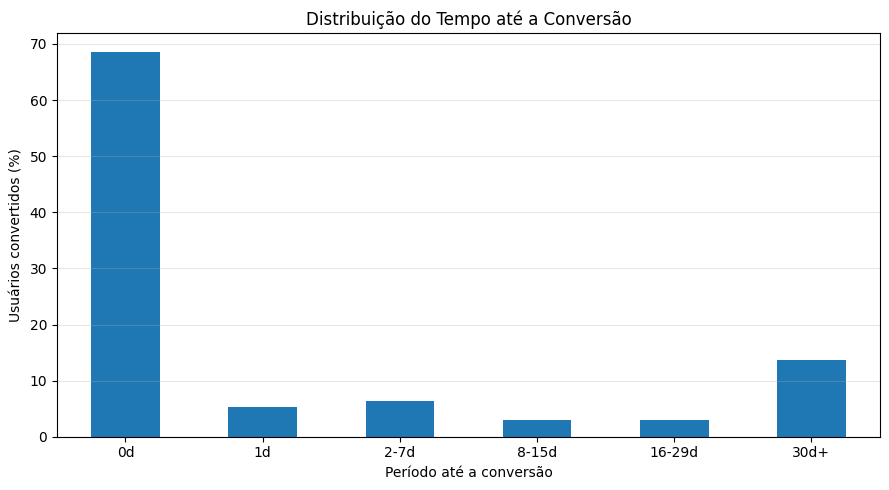

In [37]:
# dispositivo da primeira visita de cada usuário
first_device = (
    visits
    .sort_values('Start Ts')
    .drop_duplicates('Uid')
    [['Uid', 'Device']]
    .rename(columns={'Device': 'first_device'})
)

# evitar duplicação caso a célula seja executada novamente
if 'first_device' in conversion.columns:
    conversion = conversion.drop(
        columns=['first_device']
    )

# adicionar dispositivo da primeira visita à conversão
conversion = conversion.merge(
    first_device,
    on='Uid',
    how='left'
)

# criar períodos de conversão
def conversion_period(days):

    if pd.isna(days):
        return 'não converteu'

    elif days == 0:
        return '0d'

    elif days == 1:
        return '1d'

    elif days <= 7:
        return '2-7d'

    elif days <= 15:
        return '8-15d'

    elif days < 30:
        return '16-29d'

    else:
        return '30d+'


conversion['conversion_period'] = (
    conversion['conversion_day']
    .apply(conversion_period)
)

# visualizar os dados
print(
    conversion[
        [
            'Uid',
            'first_visit',
            'first_order',
            'conversion_day',
            'first_device',
            'conversion_period'
        ]
    ].head(10)
)

# ordem das faixas
period_order = [
    '0d',
    '1d',
    '2-7d',
    '8-15d',
    '16-29d',
    '30d+'
]

# distribuição dos usuários que converteram
conversion_period_data = (
    conversion[
        conversion['conversion_period'] != 'não converteu'
    ]
    .groupby('conversion_period')['Uid']
    .nunique()
    .reindex(period_order)
)

# transformar em porcentagem
conversion_period_pct = (
    conversion_period_data
    / conversion_period_data.sum()
    * 100
)

# gráfico
conversion_period_pct.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Distribuição do Tempo até a Conversão')
plt.xlabel('Período até a conversão')
plt.ylabel('Usuários convertidos (%)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


MÉDIA E MEDIANA DE CONVERSÃO POR DISPOSITIVO:
              median_conversion_days  mean_conversion_days
first_device                                              
desktop                         0.01                 16.01
touch                           0.03                 20.47

TAXA DE CONVERSÃO POR DISPOSITIVO:
              total_users  converted_users  conversion_rate
first_device                                               
desktop            160795            29211            18.17
touch               67374             7312            10.85

PARTICIPAÇÃO DOS DISPOSITIVOS:
              total_users  share_users  converted_users  share_converted  \
first_device                                                               
desktop            160795        70.47            29211            79.98   
touch               67374        29.53             7312            20.02   

              conversion_rate  
first_device                   
desktop                 18.17  
touch   

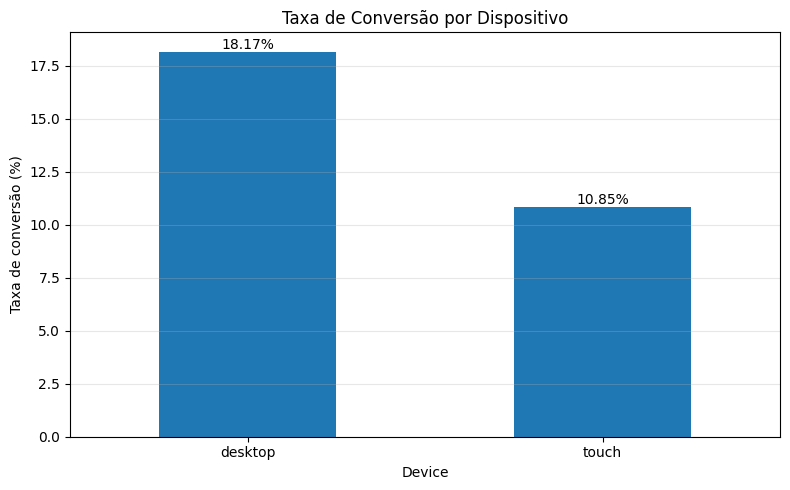

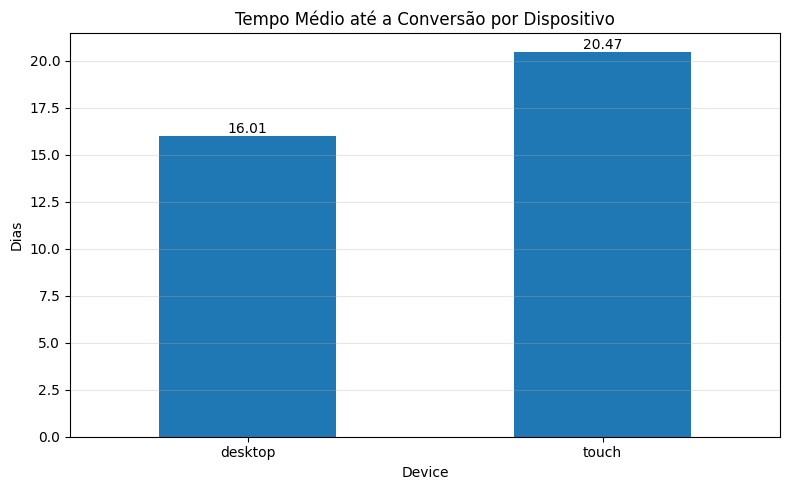

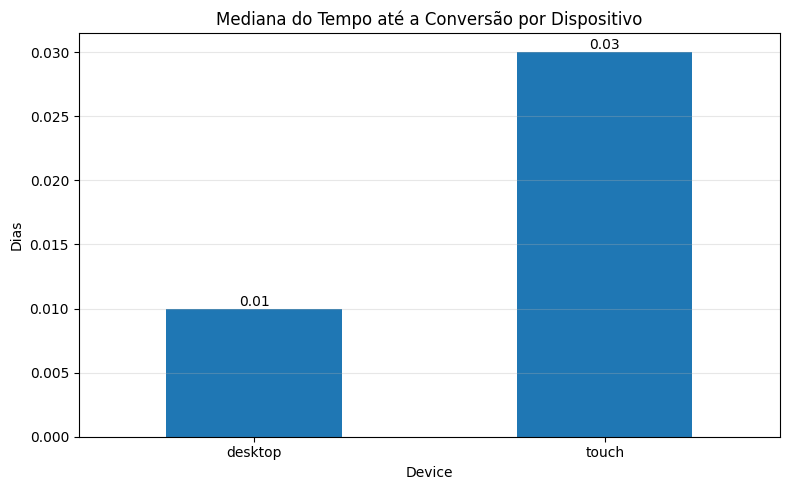

In [38]:
# média e mediana do tempo de conversão por dispositivo
conversion_by_device = (
    conversion
    .dropna(subset=['conversion_days_exact'])
    .groupby('first_device')
    .agg(
        median_conversion_days=(
            'conversion_days_exact',
            'median'
        ),
        mean_conversion_days=(
            'conversion_days_exact',
            'mean'
        )
    )
    .round(2)
)

print(
    '\nMÉDIA E MEDIANA DE CONVERSÃO POR DISPOSITIVO:'
)
print(conversion_by_device)


# taxa de conversão por dispositivo
conversion_rate_device = (
    conversion
    .groupby('first_device')
    .agg(
        total_users=('Uid', 'nunique'),
        converted_users=(
            'first_order',
            lambda x: x.notna().sum()
        )
    )
)

conversion_rate_device['conversion_rate'] = (
    conversion_rate_device['converted_users']
    / conversion_rate_device['total_users']
    * 100
).round(2)

print(
    '\nTAXA DE CONVERSÃO POR DISPOSITIVO:'
)
print(conversion_rate_device)


# total de usuários convertidos
total_converted = (
    conversion_rate_device[
        'converted_users'
    ].sum()
)

# participação de cada device nas conversões
conversion_rate_device['share_converted'] = (
    conversion_rate_device['converted_users']
    / total_converted
    * 100
).round(2)


# total de usuários
total_users = (
    conversion_rate_device[
        'total_users'
    ].sum()
)

# participação de cada device na base
conversion_rate_device['share_users'] = (
    conversion_rate_device['total_users']
    / total_users
    * 100
).round(2)

print(
    '\nPARTICIPAÇÃO DOS DISPOSITIVOS:'
)

print(
    conversion_rate_device[
        [
            'total_users',
            'share_users',
            'converted_users',
            'share_converted',
            'conversion_rate'
        ]
    ]
)


# gráfico da taxa de conversão por dispositivo
conversion_rate_device[
    'conversion_rate'
].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Taxa de Conversão por Dispositivo')
plt.xlabel('Device')
plt.ylabel('Taxa de conversão (%)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

for i, value in enumerate(
    conversion_rate_device['conversion_rate']
):
    plt.text(
        i,
        value,
        f'{value:.2f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()


# gráfico da média do tempo de conversão
conversion_by_device[
    'mean_conversion_days'
].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Tempo Médio até a Conversão por Dispositivo')
plt.xlabel('Device')
plt.ylabel('Dias')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

for i, value in enumerate(
    conversion_by_device['mean_conversion_days']
):
    plt.text(
        i,
        value,
        f'{value:.2f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()


# gráfico da mediana do tempo de conversão
conversion_by_device[
    'median_conversion_days'
].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Mediana do Tempo até a Conversão por Dispositivo')
plt.xlabel('Device')
plt.ylabel('Dias')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

for i, value in enumerate(
    conversion_by_device['median_conversion_days']
):
    plt.text(
        i,
        value,
        f'{value:.2f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

RETENÇÃO MÉDIA PONDERADA POR DEVICE (%):
first_device  desktop   touch
lifetime                     
0              100.00  100.00
1                6.65    6.10
2                4.62    3.92
3                4.13    3.35
4                3.88    3.04
5                3.78    2.81
6                3.56    2.69
7                3.72    2.66
8                3.87    2.61
9                3.98    2.61
10               3.70    2.67
11               4.91    3.38

NÚMERO DE COORTES DISPONÍVEIS:
first_device  desktop  touch
lifetime                    
0                  12     12
1                  11     11
2                  10     10
3                   9      9
4                   8      8
5                   7      7
6                   6      6
7                   5      5
8                   4      4
9                   3      3
10                  2      2
11                  1      1


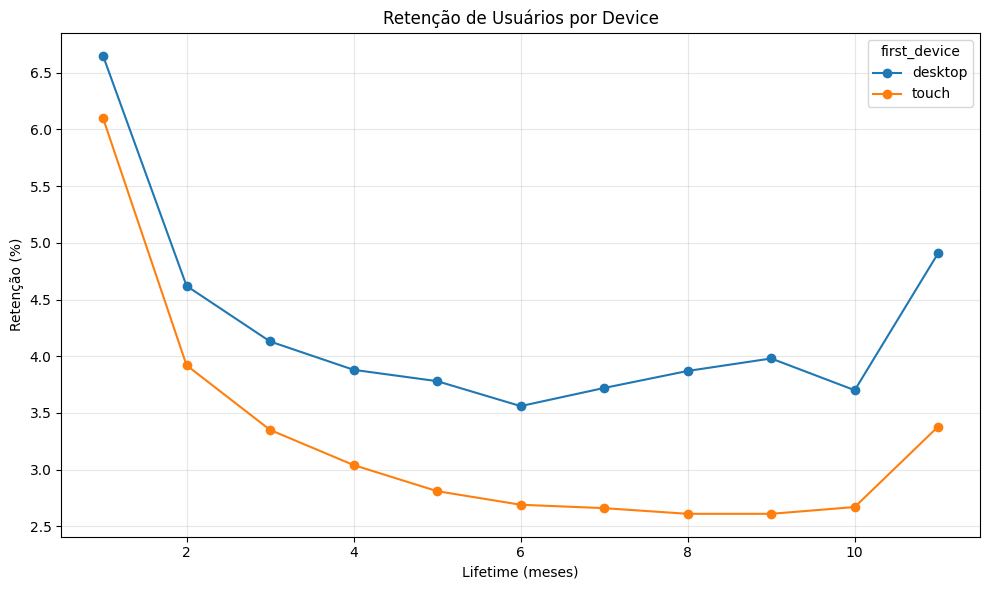

In [39]:
# retenção por device com média ponderada pelo tamanho das coortes

# garantir o device da primeira visita
first_device = (
    visits
    .sort_values('Start Ts')
    .drop_duplicates('Uid')
    [['Uid', 'Device']]
    .rename(columns={'Device': 'first_device'})
)

# criar base para retenção
visits_retention = visits.copy()

# evitar duplicação caso a célula seja executada novamente
if 'first_device' in visits_retention.columns:
    visits_retention = visits_retention.drop(
        columns=['first_device']
    )

visits_retention = visits_retention.merge(
    first_device,
    on='Uid',
    how='left'
)

# mês da atividade
visits_retention['activity_month'] = (
    visits_retention['Start Ts']
    .dt.to_period('M')
    .dt.to_timestamp()
)

# primeiro mês de atividade de cada usuário
visits_retention['first_activity_month'] = (
    visits_retention
    .groupby('Uid')['activity_month']
    .transform('min')
)

# lifetime em meses
visits_retention['lifetime'] = (
    (
        visits_retention['activity_month'].dt.year
        - visits_retention['first_activity_month'].dt.year
    ) * 12
    +
    (
        visits_retention['activity_month'].dt.month
        - visits_retention['first_activity_month'].dt.month
    )
)

# usuários ativos por coorte, device e lifetime
retention_device_data = (
    visits_retention
    .groupby(
        [
            'first_device',
            'first_activity_month',
            'lifetime'
        ],
        as_index=False
    )
    .agg(
        retained_users=('Uid', 'nunique')
    )
)

# tamanho inicial de cada coorte
cohort_sizes_device = (
    retention_device_data[
        retention_device_data['lifetime'] == 0
    ]
    [
        [
            'first_device',
            'first_activity_month',
            'retained_users'
        ]
    ]
    .rename(
        columns={
            'retained_users': 'cohort_size'
        }
    )
)

# adicionar tamanho da coorte
retention_device_data = retention_device_data.merge(
    cohort_sizes_device,
    on=[
        'first_device',
        'first_activity_month'
    ],
    how='left'
)

# retenção de cada coorte
retention_device_data['retention_pct'] = (
    retention_device_data['retained_users']
    / retention_device_data['cohort_size']
    * 100
)

# retenção ponderada por tamanho das coortes
retention_weighted_device = (
    retention_device_data
    .groupby(
        [
            'lifetime',
            'first_device'
        ],
        as_index=False
    )
    .agg(
        retained_users=('retained_users', 'sum'),
        cohort_size=('cohort_size', 'sum'),
        n_cohorts=('first_activity_month', 'nunique')
    )
)

retention_weighted_device['retention_pct'] = (
    retention_weighted_device['retained_users']
    / retention_weighted_device['cohort_size']
    * 100
)

# tabela final
retention_by_device = (
    retention_weighted_device
    .pivot(
        index='lifetime',
        columns='first_device',
        values='retention_pct'
    )
    .round(2)
)

print(
    'RETENÇÃO MÉDIA PONDERADA POR DEVICE (%):'
)
print(retention_by_device)


# número de coortes disponíveis
cohorts_retention_device = (
    retention_weighted_device
    .pivot(
        index='lifetime',
        columns='first_device',
        values='n_cohorts'
    )
)

print(
    '\nNÚMERO DE COORTES DISPONÍVEIS:'
)
print(cohorts_retention_device)


# gráfico excluindo lifetime 0 para visualizar melhor as diferenças
retention_by_device.loc[
    retention_by_device.index > 0
].plot(
    kind='line',
    figsize=(10, 6),
    marker='o'
)

plt.title(
    'Retenção de Usuários por Device'
)

plt.xlabel(
    'Lifetime (meses)'
)

plt.ylabel(
    'Retenção (%)'
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()
plt.show()


In [41]:
orders['order_month'] = orders['Buy Ts'].dt.to_period('M').dt.to_timestamp()
orders_complete = orders[orders['order_month'] < '2018-06-01'].copy()

# retirando junho incompleto das comparações mensais
orders_complete = orders[
    orders['order_month'] < '2018-06-01'
].copy()

#refazendo a tabela sem o mês de junho
orders_per_month = (
    orders_complete
    .groupby('order_month')
    .agg(
        total_orders=('Uid', 'count'),
        unique_buyers=('Uid', 'nunique')
    )
)

orders_per_month['orders_per_buyer'] = (
    orders_per_month['total_orders']
    / orders_per_month['unique_buyers']
).round(2)

print(orders_per_month)

             total_orders  unique_buyers  orders_per_buyer
order_month                                               
2017-06-01           2354           2023              1.16
2017-07-01           2363           1984              1.19
2017-08-01           1807           1472              1.23
2017-09-01           3387           2750              1.23
2017-10-01           5679           4675              1.21
2017-11-01           5659           4547              1.24
2017-12-01           6218           4942              1.26
2018-01-01           4721           3898              1.21
2018-02-01           5281           4258              1.24
2018-03-01           5326           4181              1.27
2018-04-01           3273           2744              1.19
2018-05-01           4346           3544              1.23


# Observações: #
Retirei o mês de junho, pois na ánalise ele pode atrapalhar alguns resultados, pois só temos um dia registrado no mês de junho contra 30 dias registrados nos outros meses 

In [42]:
# dispositivo da primeira visita de cada usuário
first_device = (
    visits
    .sort_values('Start Ts')
    .drop_duplicates('Uid')
    [['Uid', 'Device']]
)

# adicionando device aos pedidos
orders_device = orders_complete.merge(
    first_device,
    on='Uid',
    how='left'
)

# pedidos por mês e dispositivo
orders_per_month_device = (
    orders_device
    .groupby(['order_month', 'Device'])
    .agg(
        total_orders=('Uid', 'count'),
        unique_buyers=('Uid', 'nunique')
    )
)

# média de pedidos por comprador por mês
orders_per_month_device['orders_per_buyer'] = (
    orders_per_month_device['total_orders']
    / orders_per_month_device['unique_buyers']
).round(2)

print(orders_per_month_device)

# quantidade de pedidos de cada comprador por device
orders_per_buyer_device = (
    orders_device
    .groupby(['Device', 'Uid'])
    .size()
    .reset_index(name='orders')
)

# média e mediana por dispositivo
orders_stats_device = (
    orders_per_buyer_device
    .groupby('Device')
    .agg(
        mean_orders=('orders', 'mean'),
        median_orders=('orders', 'median')
    )
    .round(2)
)

print()
print(orders_stats_device)

                     total_orders  unique_buyers  orders_per_buyer
order_month Device                                                
2017-06-01  desktop          1994           1702              1.17
            touch             360            321              1.12
2017-07-01  desktop          1889           1577              1.20
            touch             474            407              1.16
2017-08-01  desktop          1494           1200              1.25
            touch             313            272              1.15
2017-09-01  desktop          2761           2208              1.25
            touch             626            542              1.15
2017-10-01  desktop          4624           3815              1.21
            touch            1055            860              1.23
2017-11-01  desktop          4602           3705              1.24
            touch            1057            842              1.26
2017-12-01  desktop          5033           3968              

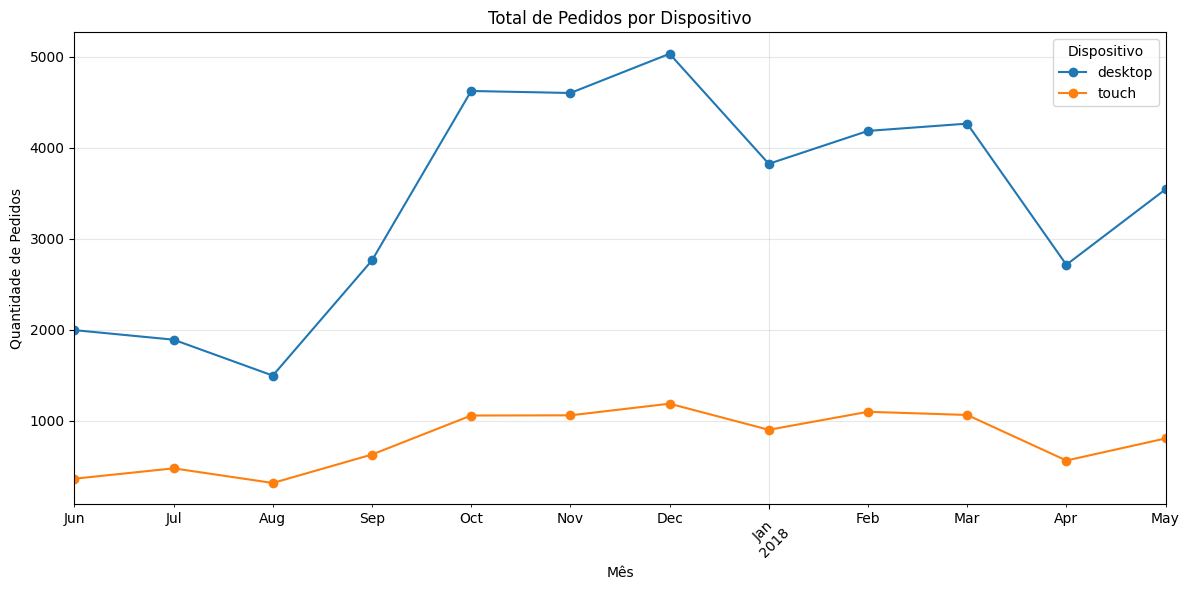

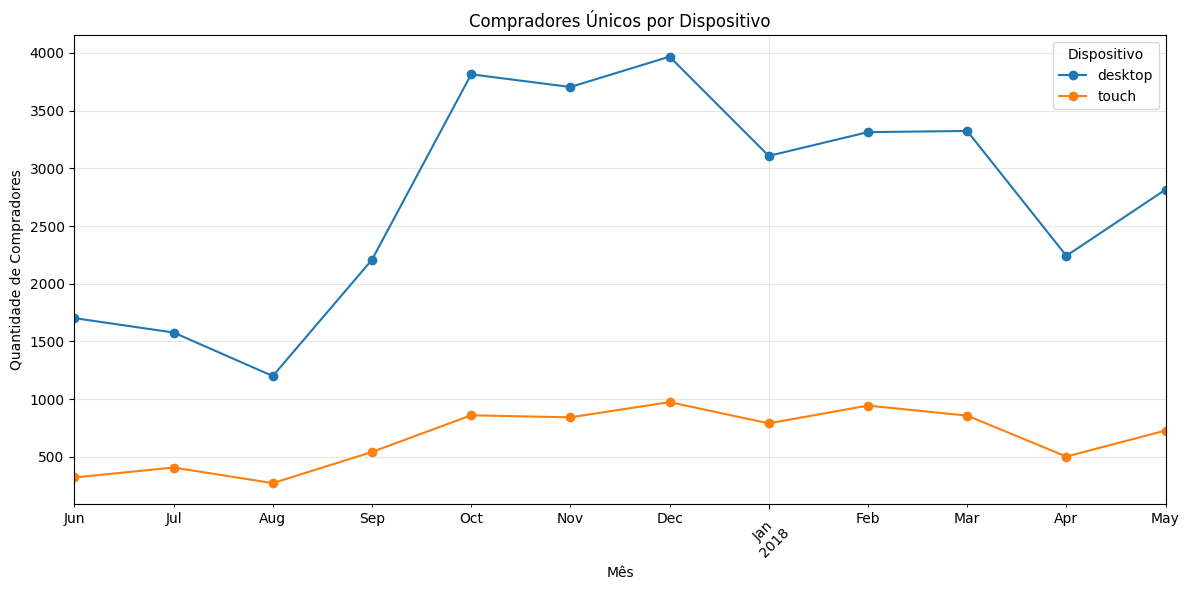

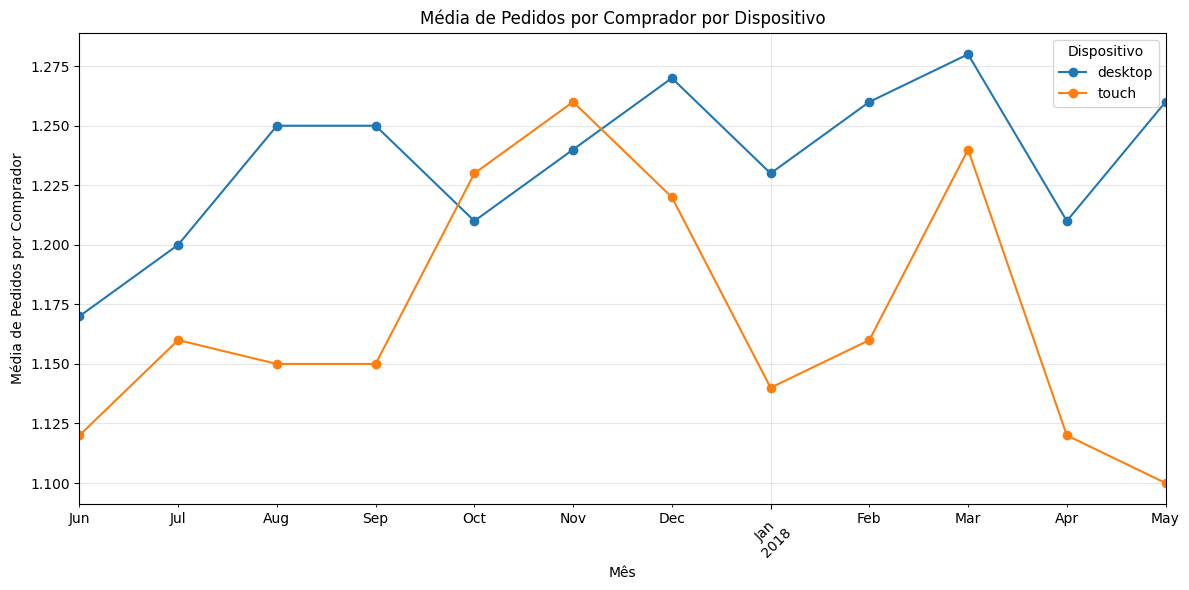

In [43]:
# pedidos totais por device
total_orders_device = (
    orders_per_month_device['total_orders']
    .unstack('Device')
)

total_orders_device.plot(
    kind='line',
    marker='o',
    figsize=(12, 6)
)

plt.title('Total de Pedidos por Dispositivo')
plt.xlabel('Mês')
plt.ylabel('Quantidade de Pedidos')
plt.xticks(rotation=45)
plt.legend(title='Dispositivo')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# compradores únicos por device
unique_buyers_device = (
    orders_per_month_device['unique_buyers']
    .unstack('Device')
)

unique_buyers_device.plot(
    kind='line',
    marker='o',
    figsize=(12, 6)
)

plt.title('Compradores Únicos por Dispositivo')
plt.xlabel('Mês')
plt.ylabel('Quantidade de Compradores')
plt.xticks(rotation=45)
plt.legend(title='Dispositivo')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# média de pedidos por comprador por device
orders_per_buyer_device_plot = (
    orders_per_month_device['orders_per_buyer']
    .unstack('Device')
)

orders_per_buyer_device_plot.plot(
    kind='line',
    marker='o',
    figsize=(12, 6)
)

plt.title('Média de Pedidos por Comprador por Dispositivo')
plt.xlabel('Mês')
plt.ylabel('Média de Pedidos por Comprador')
plt.xticks(rotation=45)
plt.legend(title='Dispositivo')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Conclusão: #
O desktop apresenta volume de pedidos e compradores bem maior que o touch. Porém, a média de pedidos por comprador é parecida entre os dispositivos, indicando que a diferença está mais no volume de usuários do que na frequência de compra.

In [44]:
# ticket médio geral
average_order_value = (
    orders_complete['Revenue']
    .mean()
)

print(
    'Ticket médio:',
    round(average_order_value, 2)
)
# ticket médio desktop
ticket_medio_desktop = (
    orders_device.loc[
        orders_device['Device'] == 'desktop',
        'Revenue'
    ]
    .mean()
)

# ticket médio touch
ticket_medio_touch = (
    orders_device.loc[
        orders_device['Device'] == 'touch',
        'Revenue'
    ]
    .mean()
)

print(
    'Ticket médio desktop:',
    round(ticket_medio_desktop, 2)
)

print(
    'Ticket médio touch:',
    round(ticket_medio_touch, 2)
)



Ticket médio: 5.0
Ticket médio desktop: 5.16
Ticket médio touch: 4.29


# Calculando o Ltv #

In [45]:

# primeira compra de cada usuário para o LTV
first_orders_ltv = (
    orders_complete
    .groupby('Uid', as_index=False)
    .agg({'Buy Ts': 'min'})
    .rename(columns={'Buy Ts': 'first_order'})
)

# mês da primeira compra
first_orders_ltv['first_order_month'] = (
    first_orders_ltv['first_order']
    .dt.to_period('M')
    .dt.to_timestamp()
)

# tamanho das coortes
ltv_cohort_sizes = (
    first_orders_ltv
    .groupby('first_order_month', as_index=False)
    .agg(n_buyers=('Uid', 'nunique'))
)

print(ltv_cohort_sizes)

# adicionar mês da primeira compra aos pedidos
orders_ltv = orders_complete.merge(
    first_orders_ltv[
        ['Uid', 'first_order_month']
    ],
    on='Uid',
    how='left'
)

# lifetime em meses
orders_ltv['age'] = (
    (
        orders_ltv['order_month'].dt.year
        - orders_ltv['first_order_month'].dt.year
    ) * 12
    +
    (
        orders_ltv['order_month'].dt.month
        - orders_ltv['first_order_month'].dt.month
    )
)

# receita por coorte e lifetime
cohort_revenue = (
    orders_ltv
    .groupby(
        ['first_order_month', 'age'],
        as_index=False
    )
    .agg(revenue=('Revenue', 'sum'))
)

# adicionar tamanho das coortes
ltv_report = cohort_revenue.merge(
    ltv_cohort_sizes,
    on='first_order_month',
    how='left'
)

# margem de 40%
margin_rate = 0.4

# lucro bruto
ltv_report['gp'] = (
    ltv_report['revenue']
    * margin_rate
)

# LTV mensal
ltv_report['ltv'] = (
    ltv_report['gp']
    / ltv_report['n_buyers']
)

# tabela de LTV mensal por coorte
ltv_pivot = ltv_report.pivot_table(
    index='first_order_month',
    columns='age',
    values='ltv',
    aggfunc='mean'
).round(2)

print(ltv_pivot)

# LTV acumulado por coorte
cum_ltv = (
    ltv_pivot
    .cumsum(axis=1)
)

print(cum_ltv.round(2))


   first_order_month  n_buyers
0         2017-06-01      2023
1         2017-07-01      1923
2         2017-08-01      1370
3         2017-09-01      2581
4         2017-10-01      4340
5         2017-11-01      4081
6         2017-12-01      4383
7         2018-01-01      3373
8         2018-02-01      3651
9         2018-03-01      3533
10        2018-04-01      2276
11        2018-05-01      2988
age                  0     1     2     3     4     5     6     7     8     9   \
first_order_month                                                               
2017-06-01         1.89  0.19  0.18  0.38  0.41  0.29  0.38  0.23  0.22  0.24   
2017-07-01         2.40  0.13  0.25  0.14  0.07  0.06  0.05  0.06  0.06  0.06   
2017-08-01         2.11  0.19  0.18  0.16  0.20  0.11  0.08  0.16  0.12  0.08   
2017-09-01         2.26  0.45  0.21  1.59  0.16  0.26  0.28  0.10  0.07   NaN   
2017-10-01         2.00  0.21  0.08  0.06  0.06  0.05  0.03  0.05   NaN   NaN   
2017-11-01         2.06  0.16 

# observação: #
Foi considerada uma margem de 40%, conforme a metodologia adotada no projeto, para transformar a receita em lucro bruto antes do cálculo do LTV.

In [46]:
# investigar o pico da coorte de setembro/2017 no lifetime 3
check_outlier = orders_ltv[
    (orders_ltv['first_order_month'] == '2017-09-01')
    &
    (orders_ltv['age'] == 3)
].copy()

print('ESTATÍSTICAS DA RECEITA:')
print(
    check_outlier['Revenue'].describe()
)

print('\nNÚMERO DE PEDIDOS:')
print(
    check_outlier.shape[0]
)

print('\nCOMPRADORES ATIVOS:')
print(
    check_outlier['Uid'].nunique()
)

print('\nMAIORES PEDIDOS:')
print(
    check_outlier[
        ['Uid', 'Buy Ts', 'Revenue']
    ]
    .sort_values('Revenue', ascending=False)
    .head(10)
)

ESTATÍSTICAS DA RECEITA:
count     164.000000
mean       62.570244
std       237.649021
min         0.030000
25%         1.575000
50%         5.530000
75%        27.577500
max      2633.280000
Name: Revenue, dtype: float64

NÚMERO DE PEDIDOS:
164

COMPRADORES ATIVOS:
74

MAIORES PEDIDOS:
                       Uid              Buy Ts  Revenue
23244  5539673724080479777 2017-12-10 20:17:00  2633.28
23165  5539673724080479777 2017-12-10 13:04:00  1195.64
24341  5539673724080479777 2017-12-15 21:22:00   604.39
21961  5539673724080479777 2017-12-05 00:50:00   402.72
22769  5539673724080479777 2017-12-08 12:25:00   360.55
21906  5539673724080479777 2017-12-04 18:40:00   344.36
24775  5539673724080479777 2017-12-18 19:07:00   337.33
25480  5539673724080479777 2017-12-22 19:43:00   304.94
23483  5539673724080479777 2017-12-11 23:52:00   293.03
23196  5539673724080479777 2017-12-10 15:58:00   243.83


In [47]:
#chegando o possivel outlier 
# receita total da coorte no age 3
total_revenue = check_outlier['Revenue'].sum()

# receita do usuário com maior impacto
top_user_revenue = (
    check_outlier[
        check_outlier['Uid'] == 5539673724080479777
    ]['Revenue']
    .sum()
)

# participação desse usuário na receita
top_user_share = (
    top_user_revenue
    / total_revenue
    * 100
)

print(
    'Receita total da coorte:',
    round(total_revenue, 2)
)

print(
    'Receita do usuário outlier:',
    round(top_user_revenue, 2)
)

print(
    'Participação do usuário na receita:',
    round(top_user_share, 2),
    '%'
)

Receita total da coorte: 10261.52
Receita do usuário outlier: 9253.7
Participação do usuário na receita: 90.18 %


In [48]:
# sem o usuário outlier
without_outlier = check_outlier[
    check_outlier['Uid'] != 5539673724080479777
]

print(
    'Receita média com outlier:',
    round(check_outlier['Revenue'].mean(), 2)
)

print(
    'Receita média sem outlier:',
    round(without_outlier['Revenue'].mean(), 2)
)

Receita média com outlier: 62.57
Receita média sem outlier: 8.76


# resultado da analise outlier #
O pico de LTV da coorte de setembro/2017 no terceiro mês é fortemente influenciado por um único comprador de alto valor. Sem esse usuário, a receita média dos pedidos cairia de 62,57 para 8,76, portanto esse pico não representa o comportamento típico da coorte.

In [49]:

# média do LTV acumulado por lifetime
ltv_by_lifetime = (
    cum_ltv
    .mean(axis=0)
    .reset_index()
)

ltv_by_lifetime.columns = [
    'lifetime',
    'cum_ltv'
]

# número de coortes disponíveis em cada lifetime
ltv_by_lifetime['n_cohorts'] = (
    cum_ltv
    .notna()
    .sum(axis=0)
    .values
)

ltv_by_lifetime['cum_ltv'] = (
    ltv_by_lifetime['cum_ltv']
    .round(2)
)

print(ltv_by_lifetime)


    lifetime  cum_ltv  n_cohorts
0          0     1.97         12
1          1     2.16         11
2          2     2.33         10
3          3     2.67          9
4          4     2.92          8
5          5     3.19          7
6          6     3.35          6
7          7     3.63          5
8          8     4.02          4
9          9     3.69          3
10        10     3.99          2
11        11     4.74          1


# Observação : #
os lifetimes 8-11 se baseiam em apenas 1-4 coortes, o que significa que a cauda ascendente no gráfico construído a partir dessa tabela é muito menos confiável do que os pontos anteriores.

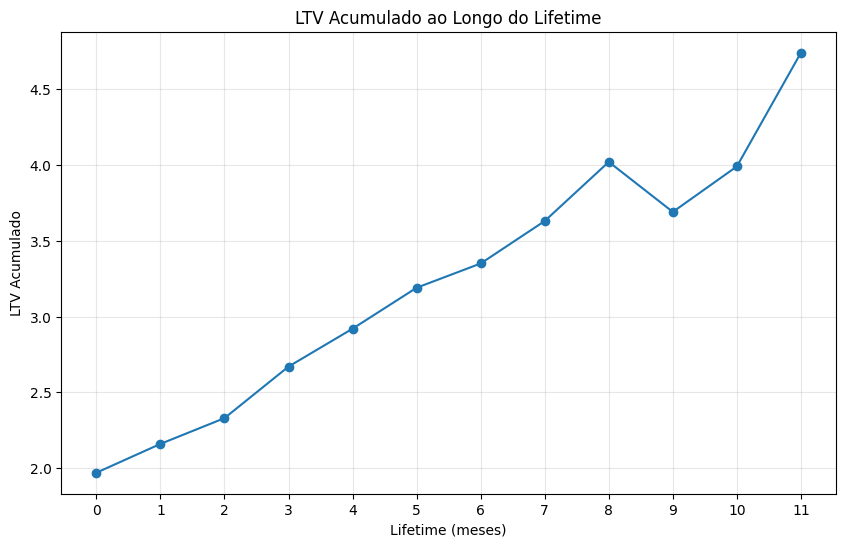

In [50]:
#grafico geral ltv de linhas
plt.figure(figsize=(10, 6))

plt.plot(
    ltv_by_lifetime['lifetime'],
    ltv_by_lifetime['cum_ltv'],
    marker='o'
)

plt.title('LTV Acumulado ao Longo do Lifetime')
plt.xlabel('Lifetime (meses)')
plt.ylabel('LTV Acumulado')
plt.xticks(ltv_by_lifetime['lifetime'])
plt.grid(alpha=0.3)

plt.show()

# Observação: # 
Os lifetimes mais altos possuem menos coortes disponíveis, portanto as oscilações no final das curvas devem ser interpretadas com cautela e podem refletir o tamanho reduzido da amostra.

LTV ACUMULADO MÉDIO PONDERADO POR LIFETIME E DEVICE:
first_device  desktop  touch
lifetime                    
0                1.96   1.86
1                2.14   2.05
2                2.32   2.14
3                2.71   2.11
4                2.97   2.22
5                3.25   2.35
6                3.35   2.61
7                3.73   2.69
8                4.46   3.02
9                4.03   2.47
10               4.37   2.45
11               5.25   2.10

NÚMERO DE COORTES DISPONÍVEIS POR LIFETIME E DEVICE:
first_device  desktop  touch
lifetime                    
0                  12     12
1                  11     11
2                  10     10
3                   9      9
4                   8      8
5                   7      7
6                   6      6
7                   5      5
8                   4      4
9                   3      3
10                  2      2
11                  1      1


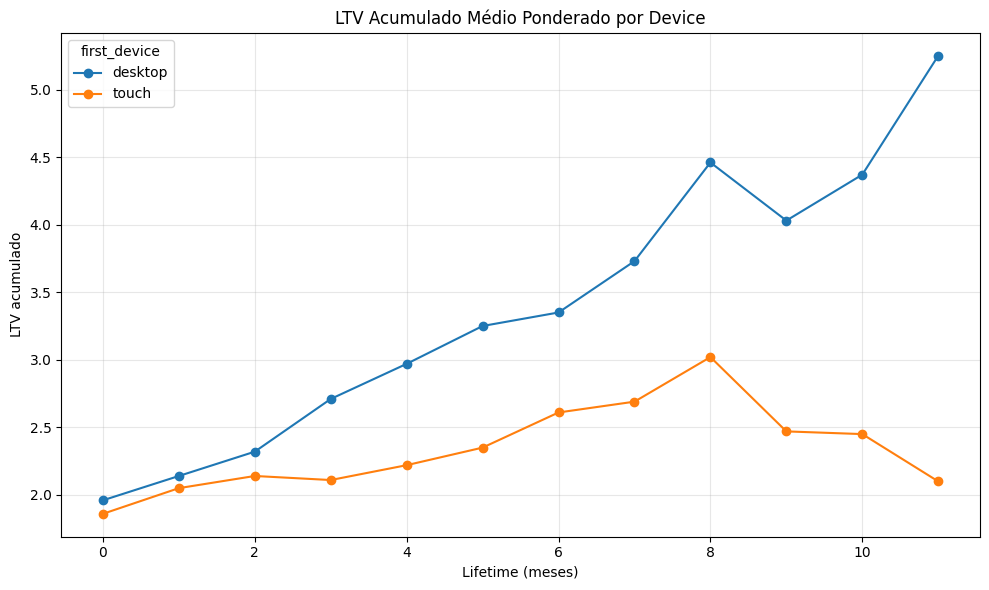

In [53]:
# analisando LTV por device

# dispositivo da primeira visita
first_device = (
    visits
    .sort_values('Start Ts')
    .drop_duplicates('Uid')
    [['Uid', 'Device']]
    .rename(columns={'Device': 'first_device'})
)

# adicionar device à primeira compra
first_orders_device = first_orders_ltv.merge(
    first_device,
    on='Uid',
    how='left'
)

# tamanho das coortes por mês e device
ltv_cohort_sizes_device = (
    first_orders_device
    .groupby(
        ['first_order_month', 'first_device'],
        as_index=False
    )
    .agg(
        n_buyers=('Uid', 'nunique')
    )
)

# adicionar coorte e device aos pedidos
orders_ltv_device = orders_complete.merge(
    first_orders_device[
        [
            'Uid',
            'first_order_month',
            'first_device'
        ]
    ],
    on='Uid',
    how='left'
)

# calcular lifetime em meses
orders_ltv_device['lifetime'] = (
    (
        orders_ltv_device['order_month'].dt.year
        - orders_ltv_device['first_order_month'].dt.year
    ) * 12
    +
    (
        orders_ltv_device['order_month'].dt.month
        - orders_ltv_device['first_order_month'].dt.month
    )
)

# receita por coorte, device e lifetime
ltv_device = (
    orders_ltv_device
    .groupby(
        [
            'first_order_month',
            'first_device',
            'lifetime'
        ],
        as_index=False
    )
    .agg(
        revenue=('Revenue', 'sum')
    )
)

# adicionar tamanho da coorte
ltv_device = ltv_device.merge(
    ltv_cohort_sizes_device,
    on=[
        'first_order_month',
        'first_device'
    ],
    how='left'
)

# margem de 40% adotada conforme a metodologia do projeto
margin_rate = 0.4

# lucro bruto
ltv_device['gp'] = (
    ltv_device['revenue']
    * margin_rate
)

# LTV mensal
ltv_device['ltv'] = (
    ltv_device['gp']
    / ltv_device['n_buyers']
)

# ordenar os dados
ltv_device = (
    ltv_device
    .sort_values(
        [
            'first_device',
            'first_order_month',
            'lifetime'
        ]
    )
)

# LTV acumulado por coorte
ltv_device['cum_ltv'] = (
    ltv_device
    .groupby(
        [
            'first_device',
            'first_order_month'
        ]
    )['ltv']
    .cumsum()
)

# ponderar pelo tamanho da coorte
ltv_device['weighted_ltv'] = (
    ltv_device['cum_ltv']
    * ltv_device['n_buyers']
)

# calcular média ponderada por lifetime e device
ltv_weighted = (
    ltv_device
    .groupby(
        [
            'lifetime',
            'first_device'
        ],
        as_index=False
    )
    .agg(
        weighted_ltv_sum=('weighted_ltv', 'sum'),
        buyers_sum=('n_buyers', 'sum')
    )
)

ltv_weighted['weighted_avg_ltv'] = (
    ltv_weighted['weighted_ltv_sum']
    / ltv_weighted['buyers_sum']
)

# tabela final de LTV por device
ltv_by_device = (
    ltv_weighted
    .pivot(
        index='lifetime',
        columns='first_device',
        values='weighted_avg_ltv'
    )
    .round(2)
)

print(
    'LTV ACUMULADO MÉDIO PONDERADO POR LIFETIME E DEVICE:'
)
print(ltv_by_device)


# número de coortes disponíveis
cohorts_by_device = (
    ltv_device
    .groupby(
        [
            'lifetime',
            'first_device'
        ]
    )['first_order_month']
    .nunique()
    .unstack()
)

print(
    '\nNÚMERO DE COORTES DISPONÍVEIS POR LIFETIME E DEVICE:'
)
print(cohorts_by_device)


# gráfico do LTV acumulado por device
ltv_by_device.plot(
    kind='line',
    figsize=(10, 6),
    marker='o'
)

plt.title(
    'LTV Acumulado Médio Ponderado por Device'
)

plt.xlabel(
    'Lifetime (meses)'
)

plt.ylabel(
    'LTV acumulado'
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [54]:
# lifetime observado dos usuários
user_lifetime = (
    visits
    .groupby('Uid')
    .agg(
        first_activity=('Start Ts', 'min'),
        last_activity=('Start Ts', 'max')
    )
    .reset_index()
)

# lifetime em dias
user_lifetime['lifetime_days'] = (
    user_lifetime['last_activity']
    - user_lifetime['first_activity']
).dt.total_seconds() / 86400

# média e mediana
mean_lifetime_days = (
    user_lifetime['lifetime_days']
    .mean()
)

median_lifetime_days = (
    user_lifetime['lifetime_days']
    .median()
)

print(
    'Lifetime médio observado:',
    round(mean_lifetime_days, 2),
    'dias'
)

print(
    'Mediana do lifetime observado:',
    round(median_lifetime_days, 2),
    'dias'
)

Lifetime médio observado: 16.17 dias
Mediana do lifetime observado: 0.0 dias


#  Resultado da Ánalise de vendas #
Na análise de vendas, cerca de 12,8% dos usuários convertem nos primeiros 7 dias, chegando a 13,28% em até 14 dias e 13,84% em até 30 dias, mostrando que a maior parte das conversões ocorre no início. Desktop apresenta taxa de conversão de 18,17%, contra 10,85% em touch, além de maior participação nas conversões. O lifetime médio observado é de aproximadamente 16 dias, com mediana próxima de zero. O ticket médio é de 5,16 para desktop e 4,29 para touch. No primeiro lifetime, o LTV é de aproximadamente 1,96 para desktop e 1,86 para touch, e a diferença aumenta ao longo dos lifetimes observados, indicando maior geração de valor acumulado para desktop.

# Analise de marketing #
Agora vamos analisar quanto dinheiro foi gasto, qual foi o retorno do investimentos, o CAC , o ROMI e todas as métricas para olhar o resultado 

In [58]:
costs = pd.read_csv('/datasets/costs_us.csv')
print(costs.nunique())
print()
print(costs.info())
print()
costs.head()


source_id       7
dt            364
costs        2396
dtype: int64

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2542 entries, 0 to 2541
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   source_id  2542 non-null   int64  
 1   dt         2542 non-null   object 
 2   costs      2542 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 59.7+ KB
None



,source_id,dt,costs
0,1,2017-06-01,75.20
1,1,2017-06-02,62.25
2,1,2017-06-03,36.53
3,1,2017-06-04,55.00
4,1,2017-06-05,57.08


In [59]:
#alteração de dados objects para datetime 
costs['dt'] = (costs['dt']
    .apply(pd.to_datetime)
                                 )
#vendo os valores unicos na coluna 
costs_counts_uni = (
    costs[['costs', 'source_id']]
    .value_counts()
    .reset_index(name='count')
)
print(costs.info())
print()
print(costs_counts_uni)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2542 entries, 0 to 2541
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   source_id  2542 non-null   int64         
 1   dt         2542 non-null   datetime64[ns]
 2   costs      2542 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(1)
memory usage: 59.7 KB
None

        costs  source_id  count
0       10.32         10      3
1       50.77          1      3
2       16.81          9      3
3       18.37         10      2
4       15.63          9      2
...       ...        ...    ...
2480    40.09         10      1
2481    40.16          1      1
2482    40.22          1      1
2483    40.28          1      1
2484  1788.28          3      1

[2485 rows x 3 columns]


Gasto total de marketing: 329131.62

GASTOS POR ORIGEM:
source_id
3     141321.63
4      61073.60
5      51757.10
2      42806.04
1      20833.27
10      5822.49
9       5517.49
Name: costs, dtype: float64

GASTOS POR MÊS:
month
2017-06-01    18015.00
2017-07-01    18240.59
2017-08-01    14790.54
2017-09-01    24368.91
2017-10-01    36322.88
2017-11-01    37907.88
2017-12-01    38315.35
2018-01-01    33518.52
2018-02-01    32723.03
2018-03-01    30415.27
2018-04-01    22289.38
2018-05-01    22224.27
Name: costs, dtype: float64


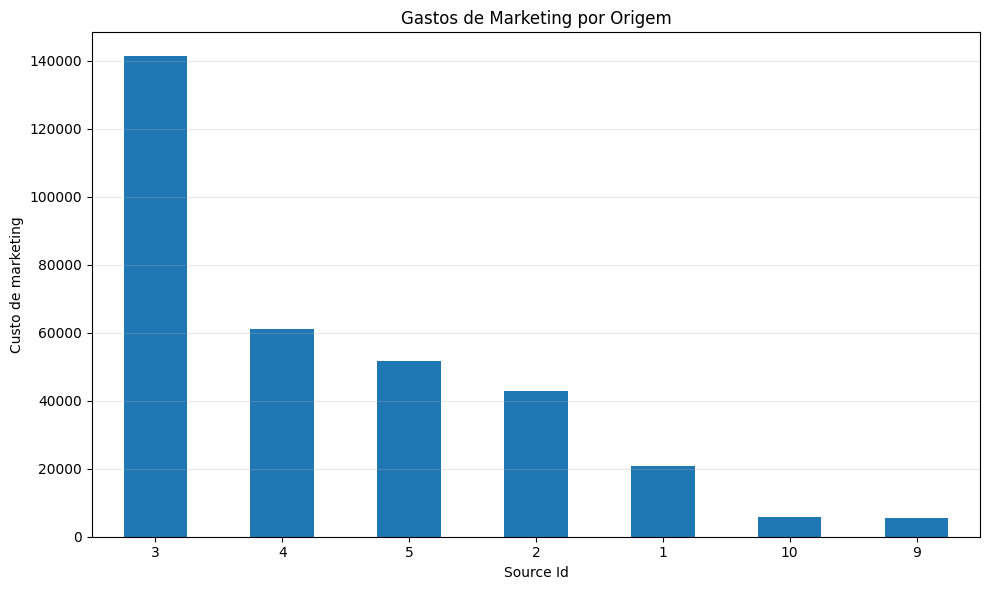

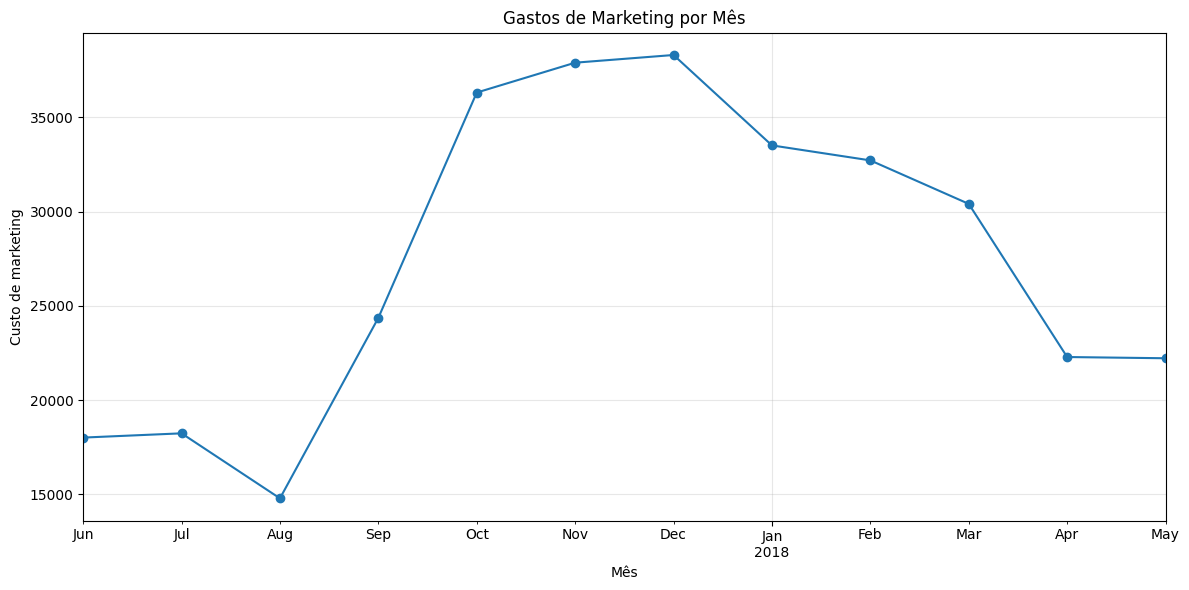

In [60]:

# garantir que dt esteja em formato datetime
costs['dt'] = pd.to_datetime(costs['dt'])

# excluir junho de 2018 por ser um mês incompleto
costs_complete = costs[
    costs['dt'] < '2018-06-01'
].copy()

# criar coluna de mês
costs_complete['month'] = (
    costs_complete['dt']
    .dt.to_period('M')
    .dt.to_timestamp()
)

# gasto total de marketing
total_marketing_cost = (
    costs_complete['costs'].sum()
)

print(
    'Gasto total de marketing:',
    round(total_marketing_cost, 2)
)

# gastos por origem
costs_by_source = (
    costs_complete
    .groupby('source_id')['costs']
    .sum()
    .sort_values(ascending=False)
)

print('\nGASTOS POR ORIGEM:')
print(costs_by_source.round(2))

# gastos por mês
costs_by_month = (
    costs_complete
    .groupby('month')['costs']
    .sum()
)

print('\nGASTOS POR MÊS:')
print(costs_by_month.round(2))


# gráfico de gastos por origem
costs_by_source.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Gastos de Marketing por Origem')
plt.xlabel('Source Id')
plt.ylabel('Custo de marketing')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


# gráfico de gastos por mês
costs_by_month.plot(
    kind='line',
    figsize=(12, 6),
    marker='o'
)

plt.title('Gastos de Marketing por Mês')
plt.xlabel('Mês')
plt.ylabel('Custo de marketing')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

CUSTO ESTIMADO POR DEVICE:
first_device
desktop    235328.30
touch       93803.32
Name: allocated_cost, dtype: float64

Custo total de marketing: 329131.62
Custo total distribuído: 329131.62

COMPRADORES POR DEVICE:
first_device
desktop    29209
touch       7312
Name: Uid, dtype: int64

CAC ESTIMADO POR DEVICE:
first_device
desktop     8.06
touch      12.83
dtype: float64

RESUMO DO CAC POR DEVICE:
              marketing_cost  buyers    CAC
first_device                               
desktop            235328.30   29209   8.06
touch               93803.32    7312  12.83


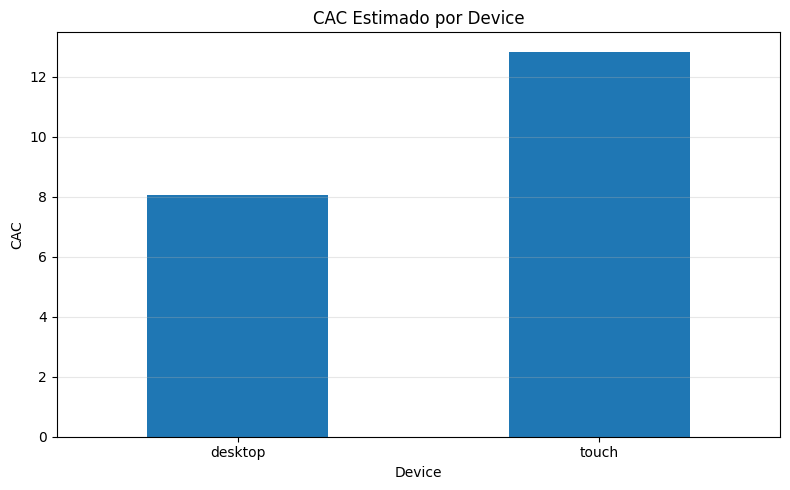

In [61]:

# CAC estimado por device

# primeira visita de cada usuário
acquisition = (
    visits
    .sort_values('Start Ts')
    .drop_duplicates('Uid')
    [
        [
            'Uid',
            'Start Ts',
            'Source Id',
            'Device'
        ]
    ]
    .rename(
        columns={
            'Start Ts': 'acquisition_date',
            'Source Id': 'source_id',
            'Device': 'first_device'
        }
    )
)

# mês de aquisição
acquisition['acquisition_month'] = (
    acquisition['acquisition_date']
    .dt.to_period('M')
    .dt.to_timestamp()
)

# origens que possuem custo de marketing registrado
paid_sources = (
    costs_complete['source_id']
    .unique()
)

# manter somente usuários de origens com custo registrado
acquisition_paid = acquisition[
    acquisition['source_id'].isin(
        paid_sources
    )
].copy()

# novos usuários por mês, origem e device
new_users_device = (
    acquisition_paid
    .groupby(
        [
            'acquisition_month',
            'source_id',
            'first_device'
        ],
        as_index=False
    )
    .agg(
        new_users=('Uid', 'nunique')
    )
)

# total de novos usuários por mês e origem
new_users_total = (
    new_users_device
    .groupby(
        [
            'acquisition_month',
            'source_id'
        ],
        as_index=False
    )
    .agg(
        total_new_users=('new_users', 'sum')
    )
)

# juntar os totais
new_users_device = new_users_device.merge(
    new_users_total,
    on=[
        'acquisition_month',
        'source_id'
    ],
    how='left'
)

# participação de cada device nos novos usuários
new_users_device['device_share'] = (
    new_users_device['new_users']
    / new_users_device['total_new_users']
)

# custo de marketing por mês e origem
costs_source_month = (
    costs_complete
    .groupby(
        [
            'month',
            'source_id'
        ],
        as_index=False
    )
    .agg(
        marketing_cost=('costs', 'sum')
    )
)

# juntar custos com participação dos devices
allocated_costs = new_users_device.merge(
    costs_source_month,
    left_on=[
        'acquisition_month',
        'source_id'
    ],
    right_on=[
        'month',
        'source_id'
    ],
    how='left'
)

# distribuir o custo proporcionalmente aos novos usuários
allocated_costs['allocated_cost'] = (
    allocated_costs['marketing_cost']
    * allocated_costs['device_share']
)

# custo estimado total por device
cost_by_device = (
    allocated_costs
    .groupby('first_device')[
        'allocated_cost'
    ]
    .sum()
)

print('CUSTO ESTIMADO POR DEVICE:')
print(
    cost_by_device.round(2)
)


# verificar se o custo distribuído é compatível com o custo total
print(
    '\nCusto total de marketing:',
    round(
        costs_complete['costs'].sum(),
        2
    )
)

print(
    'Custo total distribuído:',
    round(
        allocated_costs[
            'allocated_cost'
        ].sum(),
        2
    )
)


# compradores únicos
buyers = (
    orders_complete[
        ['Uid']
    ]
    .drop_duplicates()
)

# adicionar device e origem de aquisição aos compradores
buyers_device = buyers.merge(
    acquisition_paid[
        [
            'Uid',
            'source_id',
            'first_device'
        ]
    ],
    on='Uid',
    how='inner'
)

# compradores únicos por device
buyers_by_device = (
    buyers_device
    .groupby('first_device')['Uid']
    .nunique()
)

print(
    '\nCOMPRADORES POR DEVICE:'
)
print(
    buyers_by_device
)


# calcular CAC estimado por device
cac_device = (
    cost_by_device
    / buyers_by_device
).round(2)

print(
    '\nCAC ESTIMADO POR DEVICE:'
)
print(
    cac_device
)


# tabela final
cac_device_table = pd.DataFrame({
    'marketing_cost': cost_by_device,
    'buyers': buyers_by_device,
    'CAC': cac_device
}).round(2)

print(
    '\nRESUMO DO CAC POR DEVICE:'
)
print(
    cac_device_table
)


# gráfico do CAC estimado por device
cac_device.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title(
    'CAC Estimado por Device'
)

plt.xlabel(
    'Device'
)

plt.ylabel(
    'CAC'
)

plt.xticks(
    rotation=0
)

plt.grid(
    axis='y',
    alpha=0.3
)

plt.tight_layout()
plt.show()

MÉTRICAS DE MARKETING POR ORIGEM:
           n_buyers  marketing_cost   LTV    CAC  ROMI  ROI_pct
source_id                                                      
1              2899        20833.27  4.29   7.19  0.60   -40.31
2              3506        42806.04  5.35  12.21  0.44   -56.15
3             10473       141321.63  2.08  13.49  0.15   -84.57
4             10295        61073.60  2.20   5.93  0.37   -62.87
5              6931        51757.10  3.04   7.47  0.41   -59.33
9              1088         5517.49  2.12   5.07  0.42   -58.25
10             1329         5822.49  1.34   4.38  0.31   -69.43


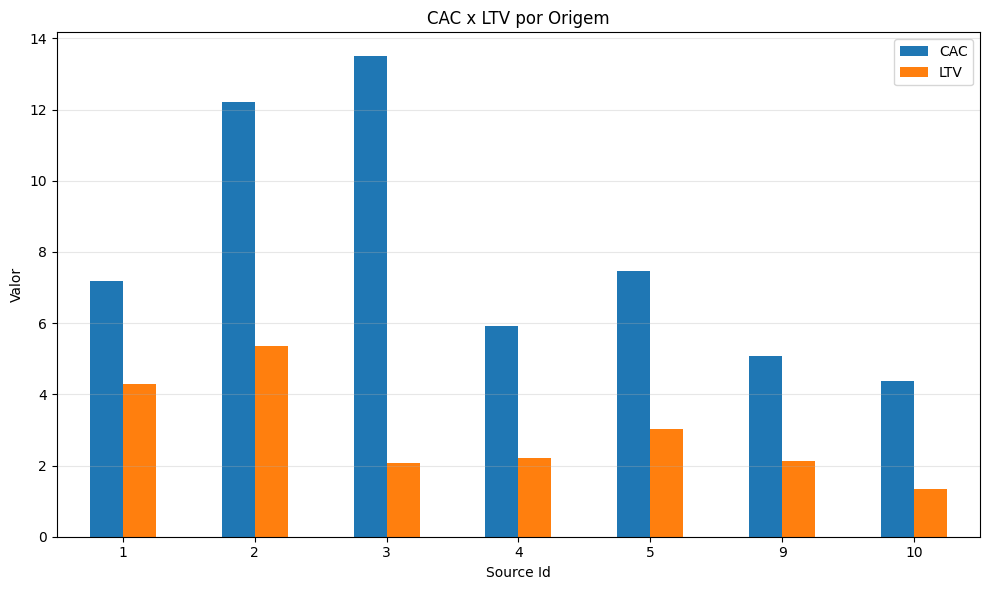

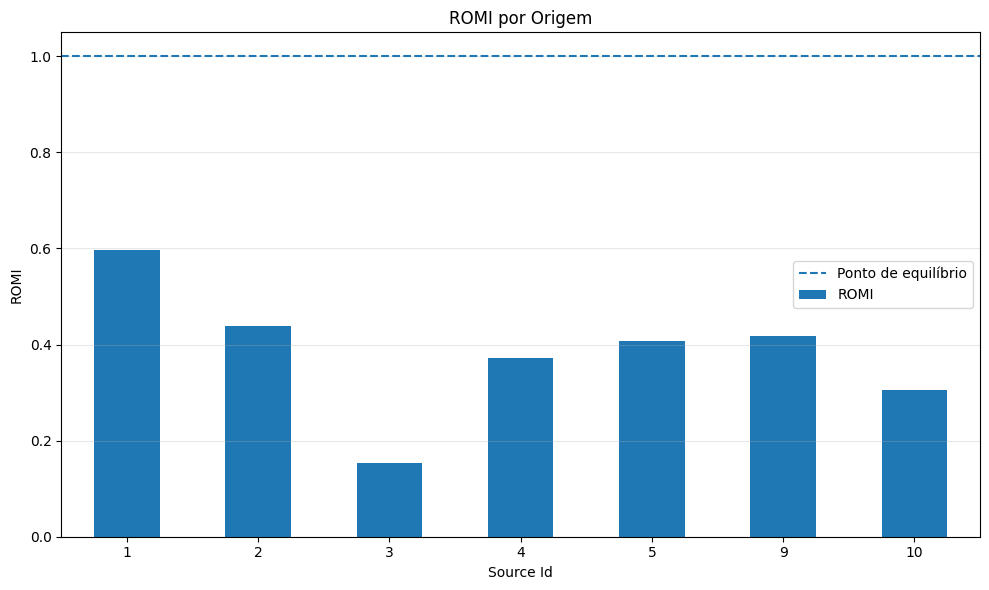


PAYBACK POR ORIGEM:
           payback_lifetime  meses_ate_payback  \
source_id                                        
1                       8.0                9.0   
2                       NaN                NaN   
3                       NaN                NaN   
4                       NaN                NaN   
5                       NaN                NaN   
9                       NaN                NaN   
10                      NaN                NaN   

                                        status  
source_id                                       
1                                      9 meses  
2          não recuperado no período observado  
3          não recuperado no período observado  
4          não recuperado no período observado  
5          não recuperado no período observado  
9          não recuperado no período observado  
10         não recuperado no período observado  

ÚLTIMO LTV/CAC OBSERVADO POR ORIGEM:
           lifetime  cum_ltv    CAC  LTV_CAC  n_c

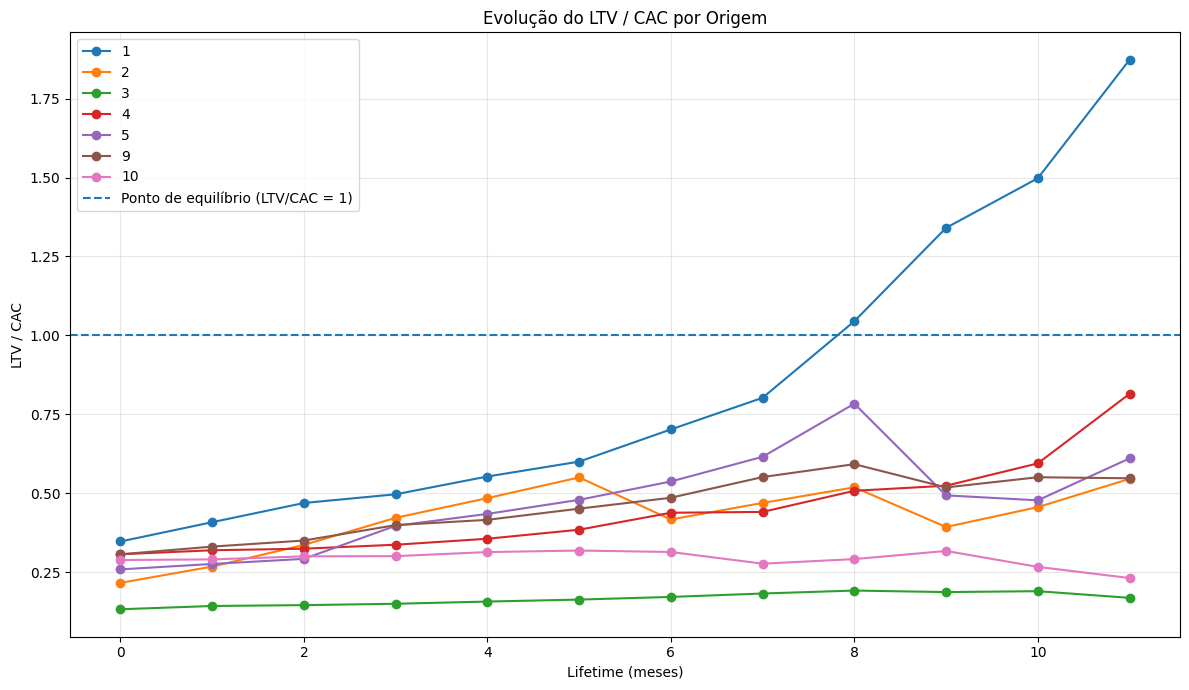

In [63]:

# CAC, LTV, ROMI, ROI e payback por origem

# garantir coluna de mês dos pedidos
orders_complete = orders_complete.copy()

orders_complete['order_month'] = (
    orders_complete['Buy Ts']
    .dt.to_period('M')
    .dt.to_timestamp()
)


# primeira origem de cada usuário
first_source = (
    visits
    .sort_values('Start Ts')
    .drop_duplicates('Uid')
    [['Uid', 'Source Id']]
    .rename(columns={'Source Id': 'source_id'})
)


# custo de marketing por origem
cost_by_source = (
    costs_complete
    .groupby('source_id')
    .agg(
        marketing_cost=('costs', 'sum')
    )
)


# adicionar origem aos pedidos
orders_source = orders_complete.merge(
    first_source,
    on='Uid',
    how='left'
)


# receita e compradores por origem
value_by_source = (
    orders_source
    .groupby('source_id')
    .agg(
        revenue=('Revenue', 'sum'),
        n_buyers=('Uid', 'nunique')
    )
)


# margem de 40% adotada conforme a metodologia do projeto
margin_rate = 0.4


# lucro bruto
value_by_source['gross_profit'] = (
    value_by_source['revenue']
    * margin_rate
)


# LTV observado por origem
value_by_source['LTV'] = (
    value_by_source['gross_profit']
    / value_by_source['n_buyers']
)


# juntar receita e custos
marketing_source = (
    value_by_source
    .merge(
        cost_by_source,
        left_index=True,
        right_index=True,
        how='inner'
    )
)


# CAC
marketing_source['CAC'] = (
    marketing_source['marketing_cost']
    / marketing_source['n_buyers']
)


# ROMI
marketing_source['ROMI'] = (
    marketing_source['LTV']
    / marketing_source['CAC']
)


# ROI percentual
marketing_source['ROI_pct'] = (
    (
        marketing_source['LTV']
        - marketing_source['CAC']
    )
    / marketing_source['CAC']
    * 100
)


print('MÉTRICAS DE MARKETING POR ORIGEM:')

print(
    marketing_source[
        [
            'n_buyers',
            'marketing_cost',
            'LTV',
            'CAC',
            'ROMI',
            'ROI_pct'
        ]
    ].round(2)
)


# gráfico CAC x LTV
marketing_source[
    ['CAC', 'LTV']
].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('CAC x LTV por Origem')
plt.xlabel('Source Id')
plt.ylabel('Valor')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


# gráfico ROMI
marketing_source[
    'ROMI'
].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.axhline(
    y=1,
    linestyle='--',
    label='Ponto de equilíbrio'
)

plt.title('ROMI por Origem')
plt.xlabel('Source Id')
plt.ylabel('ROMI')
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


# primeira compra de cada usuário
first_order_source = (
    orders_complete
    .groupby('Uid', as_index=False)
    .agg(
        first_order=('Buy Ts', 'min')
    )
)


# mês da primeira compra
first_order_source['first_order_month'] = (
    first_order_source['first_order']
    .dt.to_period('M')
    .dt.to_timestamp()
)


# adicionar origem
first_order_source = first_order_source.merge(
    first_source,
    on='Uid',
    how='left'
)


# manter apenas origens presentes em marketing_source
first_order_source = first_order_source[
    first_order_source['source_id'].isin(
        marketing_source.index
    )
].copy()


# tamanho das coortes
source_cohort_sizes = (
    first_order_source
    .groupby(
        [
            'source_id',
            'first_order_month'
        ],
        as_index=False
    )
    .agg(
        n_buyers=('Uid', 'nunique')
    )
)


# adicionar origem e coorte aos pedidos
orders_source_ltv = orders_complete.merge(
    first_order_source[
        [
            'Uid',
            'source_id',
            'first_order_month'
        ]
    ],
    on='Uid',
    how='inner'
)


# calcular lifetime em meses
orders_source_ltv['lifetime'] = (
    (
        orders_source_ltv['order_month'].dt.year
        - orders_source_ltv['first_order_month'].dt.year
    ) * 12
    +
    (
        orders_source_ltv['order_month'].dt.month
        - orders_source_ltv['first_order_month'].dt.month
    )
)


# receita por origem, coorte e lifetime
source_revenue = (
    orders_source_ltv
    .groupby(
        [
            'source_id',
            'first_order_month',
            'lifetime'
        ],
        as_index=False
    )
    .agg(
        revenue=('Revenue', 'sum')
    )
)


# último mês completo observado
last_month = (
    orders_complete['order_month'].max()
)


# lifetime máximo disponível para cada coorte
source_cohort_sizes['max_lifetime'] = (
    (
        last_month.year
        - source_cohort_sizes[
            'first_order_month'
        ].dt.year
    ) * 12
    +
    (
        last_month.month
        - source_cohort_sizes[
            'first_order_month'
        ].dt.month
    )
)


# criar todos os lifetimes possíveis
source_cohort_sizes['lifetime'] = (
    source_cohort_sizes[
        'max_lifetime'
    ].apply(
        lambda x: list(range(x + 1))
    )
)


cohort_grid = (
    source_cohort_sizes
    .explode('lifetime')
    .reset_index(drop=True)
)


cohort_grid['lifetime'] = (
    cohort_grid['lifetime']
    .astype(int)
)


# adicionar receita
cohort_grid = cohort_grid.merge(
    source_revenue,
    on=[
        'source_id',
        'first_order_month',
        'lifetime'
    ],
    how='left'
)


# meses sem compras recebem receita zero
cohort_grid['revenue'] = (
    cohort_grid['revenue']
    .fillna(0)
)


# lucro bruto
cohort_grid['gross_profit'] = (
    cohort_grid['revenue']
    * margin_rate
)


# LTV mensal
cohort_grid['ltv'] = (
    cohort_grid['gross_profit']
    / cohort_grid['n_buyers']
)


# ordenar antes do acumulado
cohort_grid = (
    cohort_grid
    .sort_values(
        [
            'source_id',
            'first_order_month',
            'lifetime'
        ]
    )
)


# LTV acumulado dentro de cada coorte
cohort_grid['cum_ltv'] = (
    cohort_grid
    .groupby(
        [
            'source_id',
            'first_order_month'
        ]
    )['ltv']
    .cumsum()
)


# ponderar pelo tamanho da coorte
cohort_grid['weighted_ltv'] = (
    cohort_grid['cum_ltv']
    * cohort_grid['n_buyers']
)


# média ponderada do LTV acumulado por origem e lifetime
ltv_source_lifetime = (
    cohort_grid
    .groupby(
        [
            'source_id',
            'lifetime'
        ],
        as_index=False
    )
    .agg(
        weighted_ltv=(
            'weighted_ltv',
            'sum'
        ),
        buyers=(
            'n_buyers',
            'sum'
        ),
        n_cohorts=(
            'first_order_month',
            'nunique'
        )
    )
)


ltv_source_lifetime['cum_ltv'] = (
    ltv_source_lifetime[
        'weighted_ltv'
    ]
    / ltv_source_lifetime[
        'buyers'
    ]
)


# adicionar CAC
ltv_source_lifetime = (
    ltv_source_lifetime
    .merge(
        marketing_source[
            ['CAC']
        ],
        left_on='source_id',
        right_index=True,
        how='left'
    )
)


# relação LTV / CAC
ltv_source_lifetime['LTV_CAC'] = (
    ltv_source_lifetime['cum_ltv']
    / ltv_source_lifetime['CAC']
)


# identificar primeiro lifetime com LTV/CAC >= 1
payback = (
    ltv_source_lifetime[
        ltv_source_lifetime[
            'LTV_CAC'
        ] >= 1
    ]
    .groupby(
        'source_id'
    )['lifetime']
    .min()
)


# tabela final de payback
payback_source = pd.DataFrame(
    index=marketing_source.index
)


payback_source['payback_lifetime'] = (
    payback
)


# lifetime 0 representa o primeiro mês
payback_source['meses_ate_payback'] = (
    payback_source['payback_lifetime']
    + 1
)


payback_source['status'] = (
    payback_source[
        'meses_ate_payback'
    ]
    .apply(
        lambda x:
        f'{int(x)} meses'
        if pd.notna(x)
        else 'não recuperado no período observado'
    )
)


print(
    '\nPAYBACK POR ORIGEM:'
)

print(
    payback_source
)


# tabela resumida do último LTV/CAC observado por origem
last_ltv_cac = (
    ltv_source_lifetime
    .sort_values('lifetime')
    .groupby('source_id')
    .tail(1)
    [
        [
            'source_id',
            'lifetime',
            'cum_ltv',
            'CAC',
            'LTV_CAC',
            'n_cohorts'
        ]
    ]
    .set_index('source_id')
    .round(2)
)


print(
    '\nÚLTIMO LTV/CAC OBSERVADO POR ORIGEM:'
)

print(
    last_ltv_cac
)


# gráfico da evolução do LTV/CAC
payback_curve = (
    ltv_source_lifetime
    .pivot(
        index='lifetime',
        columns='source_id',
        values='LTV_CAC'
    )
)


payback_curve.plot(
    kind='line',
    figsize=(12, 7),
    marker='o'
)


plt.axhline(
    y=1,
    linestyle='--',
    label='Ponto de equilíbrio (LTV/CAC = 1)'
)


plt.title(
    'Evolução do LTV / CAC por Origem'
)

plt.xlabel(
    'Lifetime (meses)'
)

plt.ylabel(
    'LTV / CAC'
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


MÉTRICAS DE MARKETING POR ORIGEM:
           n_buyers  marketing_cost   LTV    CAC  ROMI  ROI_pct
source_id                                                      
1              2899        20833.27  4.29   7.19  0.60   -40.31
2              3506        42806.04  5.35  12.21  0.44   -56.15
3             10473       141321.63  2.08  13.49  0.15   -84.57
4             10295        61073.60  2.20   5.93  0.37   -62.87
5              6931        51757.10  3.04   7.47  0.41   -59.33
9              1088         5517.49  2.12   5.07  0.42   -58.25
10             1329         5822.49  1.34   4.38  0.31   -69.43


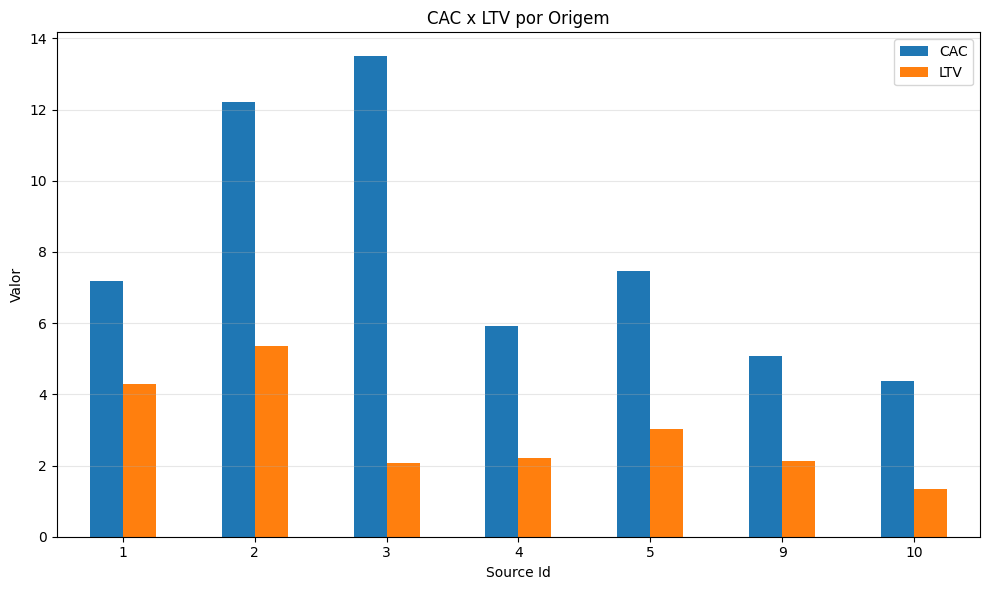

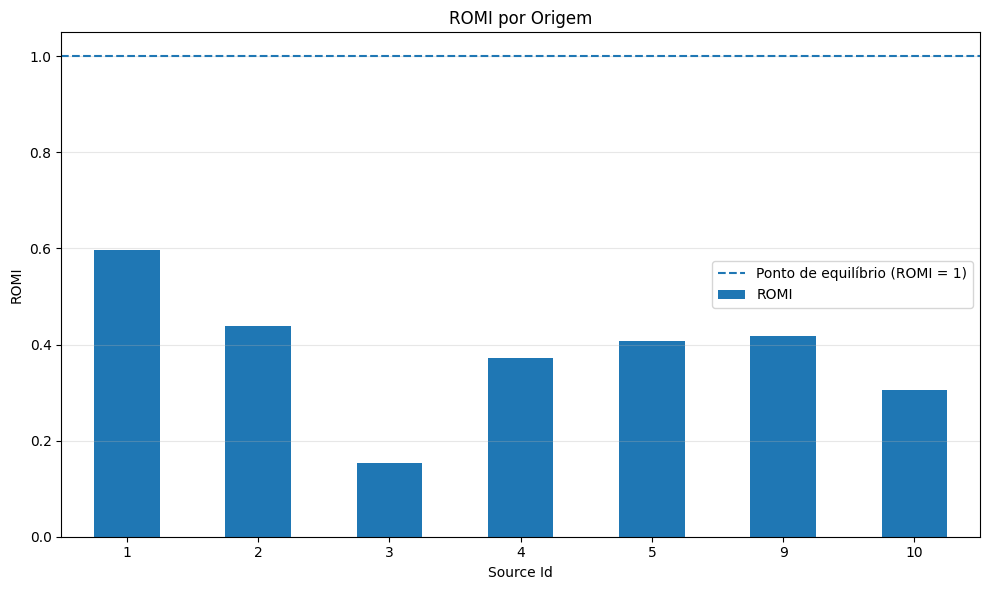

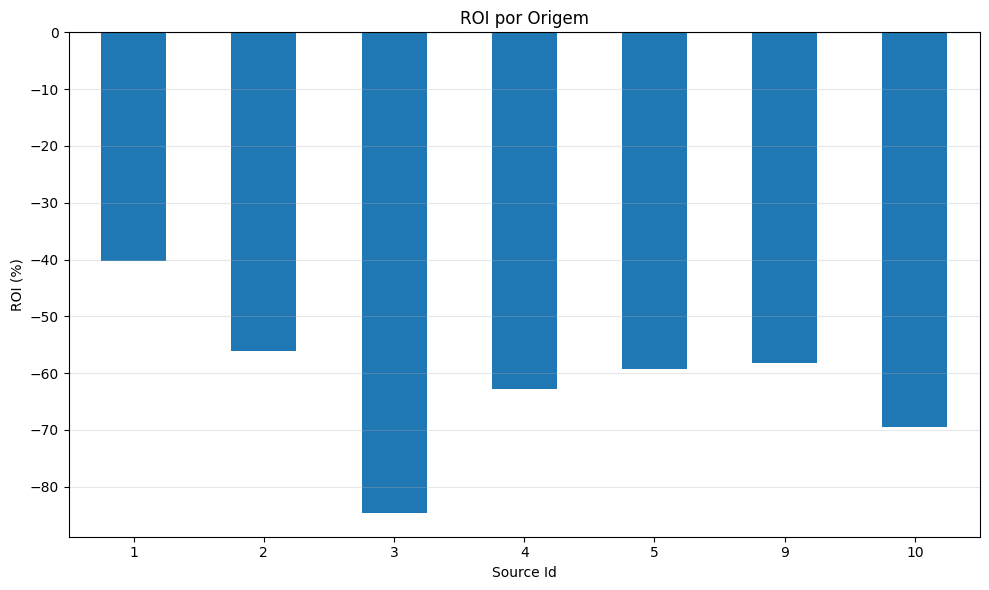

In [64]:
# primeira origem de cada usuário
first_source = (
    visits
    .sort_values('Start Ts')
    .drop_duplicates('Uid')
    [['Uid', 'Source Id']]
    .rename(columns={'Source Id': 'source_id'})
)

# custo real por origem
cost_by_source = (
    costs_complete
    .groupby('source_id')
    .agg(
        marketing_cost=('costs', 'sum')
    )
)

# adicionar origem da primeira visita aos pedidos
orders_source = orders_complete.merge(
    first_source,
    on='Uid',
    how='left'
)

# receita e compradores por origem
value_by_source = (
    orders_source
    .groupby('source_id')
    .agg(
        revenue=('Revenue', 'sum'),
        n_buyers=('Uid', 'nunique')
    )
)

# margem de 40% adotada conforme a metodologia do projeto
margin_rate = 0.4

# lucro bruto
value_by_source['gross_profit'] = (
    value_by_source['revenue']
    * margin_rate
)

# LTV observado por origem
value_by_source['LTV'] = (
    value_by_source['gross_profit']
    / value_by_source['n_buyers']
)

# juntar valor gerado e custo de marketing
marketing_source = (
    value_by_source
    .merge(
        cost_by_source,
        left_index=True,
        right_index=True,
        how='inner'
    )
)

# CAC
marketing_source['CAC'] = (
    marketing_source['marketing_cost']
    / marketing_source['n_buyers']
)

# ROMI
marketing_source['ROMI'] = (
    marketing_source['LTV']
    / marketing_source['CAC']
)

# ROI percentual
marketing_source['ROI_pct'] = (
    (
        marketing_source['LTV']
        - marketing_source['CAC']
    )
    / marketing_source['CAC']
    * 100
)

# exibir tabela final
print('MÉTRICAS DE MARKETING POR ORIGEM:')

print(
    marketing_source[
        [
            'n_buyers',
            'marketing_cost',
            'LTV',
            'CAC',
            'ROMI',
            'ROI_pct'
        ]
    ].round(2)
)


# gráfico CAC x LTV por origem
marketing_source[
    ['CAC', 'LTV']
].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('CAC x LTV por Origem')
plt.xlabel('Source Id')
plt.ylabel('Valor')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


# gráfico ROMI por origem
marketing_source[
    'ROMI'
].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.axhline(
    y=1,
    linestyle='--',
    label='Ponto de equilíbrio (ROMI = 1)'
)

plt.title('ROMI por Origem')
plt.xlabel('Source Id')
plt.ylabel('ROMI')
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


# gráfico ROI por origem
marketing_source[
    'ROI_pct'
].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.axhline(
    y=0,
    linestyle='--'
)

plt.title('ROI por Origem')
plt.xlabel('Source Id')
plt.ylabel('ROI (%)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# CONCLUSÃO DA ÁNALISE 
Para avaliar as origens de aquisição, observei principalmente no CAC, LTV e ROMI/ROI. O CAC indica quanto foi gasto de aquisição do cliente, enquanto o LTV representa o valor médio gerado por esses clientes. O ROMI permite comparar diretamente esse valor com o custo de aquisição.


Nenhuma das origens apresentou ROMI superior a 1 no período observado, indicando que o LTV ainda não foi suficiente para cobrir o CAC. Entre elas, a origem 1 apresentou o melhor desempenho relativo, com ROMI de 0,60 e ROI de -40,31%, sendo a que mais se aproximou do ponto de equilíbrio. A origem 9 apresentou CAC relativamente baixo, mas também um LTV reduzido. Já a origem 3 apresentou o resultado mais desfavorável: apesar de receber o maior investimento, teve o maior CAC e o menor ROMI, de 0,15.


Assim, se fosse necessário priorizar os investimentos com base nesses dados, a origem 1 seria a principal candidata para manutenção e otimização. Já a origem 3 deveria ser reavaliada antes de receber novos investimentos. No entanto, como nenhum canal atingiu ROMI acima de 1, os resultados não justificam simplesmente aumentar os gastos; seria importante investigar formas de reduzir o CAC ou aumentar o valor gerado pelos clientes.

**Payback — quando os gastos de marketing são cobertos:** de acordo com as tabelas `payback_source` e `last_ltv_cac`, a origem 1 é a única que recupera o seu custo de aquisição dentro do período observado. Ela atinge o break-even no lifetime 8, ou seja, cerca de 9 meses após a aquisição, e chega a um LTV/CAC de 1,87 no último lifetime disponível (lifetime 11). Já as origens 2, 3, 4, 5, 9 e 10 não atingiram o break-even até o final do período observado: no lifetime 11, o LTV acumulado cobria apenas 55% do CAC na origem 2, 17% na origem 3, 82% na origem 4, 61% na origem 5, 55% na origem 9 e 23% na origem 10. Vale lembrar que esses valores do lifetime 11 se baseiam apenas na primeira coorte, a única com 12 meses de histórico.

Portanto, apenas o investimento na origem 1 se pagou dentro do período analisado, e com um prazo longo (cerca de 9 meses). Entre as demais, a origem 4 é a que está mais próxima de se pagar, enquanto a origem 3 está muito distante do ponto de equilíbrio, o que reforça a recomendação de reavaliar os investimentos nela.